# Exploratory Data Analysis — Aerial Swarm Criticality Dataset

This notebook explores the dataset before model development. It covers data quality, case/agent/timestep structure, target and promotion behavior, feature distributions, correlations, environment/attrition effects, temporal patterns and leakage investigation.

## 1. Imports and configuration

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
warnings.filterwarnings("ignore")

DATA_PATH = "swarm_criticality_dataset_100_scenarios.csv"

## 2. Load the dataset

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Shape: (1639166, 37)
Rows: 1639166
Columns: 37


,case_id,num_agents,n_obstacles,obstacle_density,mean_obstacle_size,clutter_index,obstacle_clustering,attrition_rate,step,agent_id,rel_x,rel_y,rel_z,dist_to_centroid,rank_dist_to_centroid,dist_to_target,rank_dist_to_target,vx,vy,vz,speed,heading,flight_path_angle,accel,heading_rate,num_neighbors,mean_neighbor_dist,min_neighbor_dist,weighted_density,angular_coverage,criticality_score,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality,is_critical,was_promoted
0,c001_n60_none,60,2,0.0783,19.7896,0.6307,0.6860,none,0,0,11.1896,17.7902,21.1964,29.8494,0.2373,103.2787,0.2373,2.2750,4.4329,-0.0262,4.9826,1.0966,-0.0053,-0.3478,0.3575,44,38.7164,16.8963,2.9254,0.4792,0.6819,0.7458,0.7973,0.0096,0.0622,True,False
1,c001_n60_none,60,2,0.0783,19.7896,0.6307,0.6860,none,0,1,2.5074,-3.9590,32.6976,33.0317,0.3729,119.4049,0.5932,1.9617,4.5891,-0.0480,4.9910,1.1668,-0.0096,-0.1798,0.3575,40,35.4362,6.8414,4.7175,0.4375,0.8751,0.6780,0.7564,0.0049,0.1850,True,False
2,c001_n60_none,60,2,0.0783,19.7896,0.6307,0.6860,none,0,2,-12.4136,15.5713,-43.3000,47.6597,0.9322,101.0591,0.1864,2.6529,-4.1528,0.0474,4.9281,-1.0023,0.0096,-1.4376,0.0340,24,40.0661,14.7778,1.5280,0.2917,0.6734,0.4068,0.6277,0.0017,0.0034,True,False
3,c001_n60_none,60,2,0.0783,19.7896,0.6307,0.6860,none,0,3,10.0110,-40.4132,9.6677,42.7424,0.8136,151.4925,1.0000,0.8392,-4.8555,-0.0474,4.9277,-1.3997,-0.0096,-1.4452,-0.1979,31,41.4534,17.3229,1.2503,0.2083,0.0048,0.5254,0.6782,0.0024,0.0377,False,False
4,c001_n60_none,60,2,0.0783,19.7896,0.6307,0.6860,none,0,4,1.7406,-3.0790,-32.2032,32.3968,0.3390,118.5825,0.5424,-0.7694,-4.8152,-0.0089,4.8762,-1.7293,-0.0018,-2.4750,-0.1982,37,36.3339,5.2327,3.2188,0.4583,0.8032,0.6271,0.7284,0.0064,0.0133,True,False


## 3. Column names

In [3]:
for i, col in enumerate(df.columns):
    print(i, col)

0 case_id
1 num_agents
2 n_obstacles
3 obstacle_density
4 mean_obstacle_size
5 clutter_index
6 obstacle_clustering
7 attrition_rate
8 step
9 agent_id
10 rel_x
11 rel_y
12 rel_z
13 dist_to_centroid
14 rank_dist_to_centroid
15 dist_to_target
16 rank_dist_to_target
17 vx
18 vy
19 vz
20 speed
21 heading
22 flight_path_angle
23 accel
24 heading_rate
25 num_neighbors
26 mean_neighbor_dist
27 min_neighbor_dist
28 weighted_density
29 angular_coverage
30 criticality_score
31 degree_centrality
32 closeness_centrality
33 betweenness_centrality
34 eigenvector_centrality
35 is_critical
36 was_promoted


## 4. Dataset information

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1639166 entries, 0 to 1639165
Data columns (total 37 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   case_id                 1639166 non-null  str    
 1   num_agents              1639166 non-null  int64  
 2   n_obstacles             1639166 non-null  int64  
 3   obstacle_density        1639166 non-null  float64
 4   mean_obstacle_size      1639166 non-null  float64
 5   clutter_index           1639166 non-null  float64
 6   obstacle_clustering     1639166 non-null  float64
 7   attrition_rate          1639166 non-null  str    
 8   step                    1639166 non-null  int64  
 9   agent_id                1639166 non-null  int64  
 10  rel_x                   1639166 non-null  float64
 11  rel_y                   1639166 non-null  float64
 12  rel_z                   1639166 non-null  float64
 13  dist_to_centroid        1639166 non-null  float64
 14  rank_dist_to_

## 5. Define feature groups

In [5]:
feature_groups = {
    "Scenario / Environment": ["case_id", "num_agents", "n_obstacles", "obstacle_density",
                               "mean_obstacle_size", "clutter_index", "obstacle_clustering",
                               "attrition_rate"],
    "Simulation": ["step", "agent_id"],
    "Position": ["rel_x", "rel_y", "rel_z", "dist_to_centroid", "rank_dist_to_centroid",
                 "dist_to_target", "rank_dist_to_target"],
    "Kinematics": ["vx", "vy", "vz", "speed", "heading", "flight_path_angle",
                   "accel", "heading_rate"],
    "Local Swarm Geometry": ["num_neighbors", "mean_neighbor_dist", "min_neighbor_dist",
                             "weighted_density", "angular_coverage"],
    "Graph": ["degree_centrality", "closeness_centrality",
              "betweenness_centrality", "eigenvector_centrality"],
    "Criticality / Outcomes": ["criticality_score", "is_critical", "was_promoted"],
}

for group in feature_groups:
    print(group)
    print(feature_groups[group])
    print()

Scenario / Environment
['case_id', 'num_agents', 'n_obstacles', 'obstacle_density', 'mean_obstacle_size', 'clutter_index', 'obstacle_clustering', 'attrition_rate']

Simulation
['step', 'agent_id']

Position
['rel_x', 'rel_y', 'rel_z', 'dist_to_centroid', 'rank_dist_to_centroid', 'dist_to_target', 'rank_dist_to_target']

Kinematics
['vx', 'vy', 'vz', 'speed', 'heading', 'flight_path_angle', 'accel', 'heading_rate']

Local Swarm Geometry
['num_neighbors', 'mean_neighbor_dist', 'min_neighbor_dist', 'weighted_density', 'angular_coverage']

Graph
['degree_centrality', 'closeness_centrality', 'betweenness_centrality', 'eigenvector_centrality']

Criticality / Outcomes
['criticality_score', 'is_critical', 'was_promoted']



## 6. Data type, uniqueness, and missingness summary

In [6]:
dtype_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(),
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})
dtype_summary

,dtype,unique_values,missing_count,missing_percent
case_id,str,100,0,0.0000
num_agents,int64,9,0,0.0000
n_obstacles,int64,13,0,0.0000
obstacle_density,float64,93,0,0.0000
mean_obstacle_size,float64,93,0,0.0000
clutter_index,float64,62,0,0.0000
obstacle_clustering,float64,100,0,0.0000
attrition_rate,str,4,0,0.0000
step,int64,600,0,0.0000
agent_id,int64,75,0,0.0000


## 7. Missing-value counts

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0]

if len(missing) == 0:
    print("No missing values found.")
else:
    print(missing.sort_values(ascending=False))

No missing values found.


## 8. Missing-value percentages

In [8]:
missing_percent = df.isna().mean() * 100
missing_percent = missing_percent[missing_percent > 0]

if len(missing_percent) == 0:
    print("No missing values found.")
else:
    print(missing_percent.sort_values(ascending=False))

No missing values found.


## 9. Duplicate rows

In [9]:
print("Completely duplicated rows:", df.duplicated().sum())

Completely duplicated rows: 0


## 10. Duplicate logical keys

In [10]:
key_cols = ["case_id", "step", "agent_id"]
dup_keys = df.duplicated(subset=key_cols, keep=False)
print("Rows with a repeated (case_id, step, agent_id):", dup_keys.sum())

df[dup_keys][key_cols].sort_values(key_cols).head(30)

Rows with a repeated (case_id, step, agent_id): 0


,case_id,step,agent_id


## 11. Simulation structure

In [11]:
print("Unique case_id:", df["case_id"].nunique())
print("Unique agent_id:", df["agent_id"].nunique())
print("Unique step:", df["step"].nunique())

Unique case_id: 100
Unique agent_id: 75
Unique step: 600


## 12. Observations per case

count     100.0000
mean    16391.6600
std     10234.7821
min      3546.0000
25%      8563.5000
50%     14431.5000
75%     20815.5000
max     45000.0000
dtype: float64


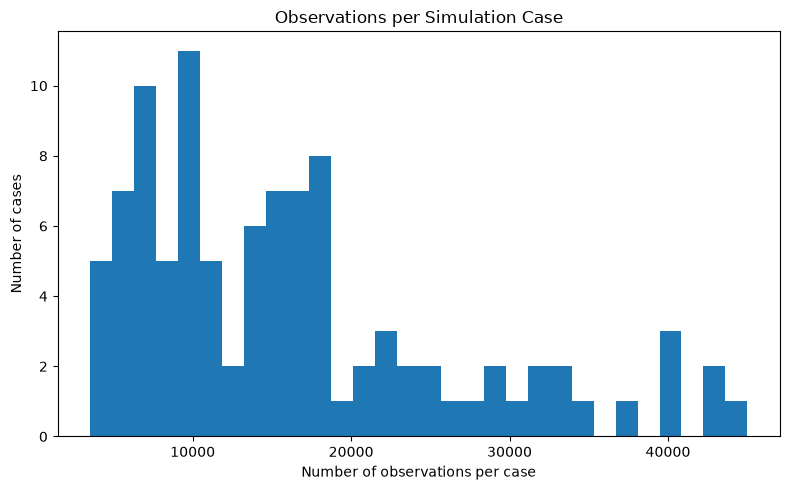

In [12]:
case_sizes = df.groupby("case_id").size()
print(case_sizes.describe())

plt.figure(figsize=(8, 5))
plt.hist(case_sizes, bins=30)
plt.xlabel("Number of observations per case")
plt.ylabel("Number of cases")
plt.title("Observations per Simulation Case")
plt.tight_layout()
plt.show()

## 13. Unique observed agents per case

In [13]:
agents_per_case = df.groupby("case_id")["agent_id"].nunique()
print(agents_per_case.describe())

count   100.0000
mean     44.8400
std      19.9285
min      18.0000
25%      28.5000
50%      45.0000
75%      60.0000
max      75.0000
Name: agent_id, dtype: float64


## 14. Declared initial agents versus observed agents

In [14]:
agent_check = df.groupby("case_id").agg(
    declared_agents=("num_agents", "first"),
    observed_agents=("agent_id", "nunique"),
)
agent_check["declared_minus_observed"] = agent_check["declared_agents"] - agent_check["observed_agents"]
print(agent_check.head(20))

print("Cases where observed agents exceed declared agents:",
      (agent_check["observed_agents"] > agent_check["declared_agents"]).sum())

                 declared_agents  observed_agents  declared_minus_observed
case_id                                                                   
c001_n60_none                 60               60                        0
c002_n30_medium               30               30                        0
c003_n37_medium               37               37                        0
c004_n30_heavy                30               30                        0
c005_n52_heavy                52               52                        0
c006_n30_none                 30               30                        0
c007_n75_light                75               75                        0
c008_n45_medium               45               45                        0
c009_n60_light                60               60                        0
c010_n45_none                 45               45                        0
c011_n45_light                45               45                        0
c012_n18_heavy           

## 15. Timesteps per case

count   100.0000
mean    377.3100
std     137.5514
min     197.0000
25%     259.0000
50%     336.5000
75%     503.5000
max     600.0000
Name: step, dtype: float64


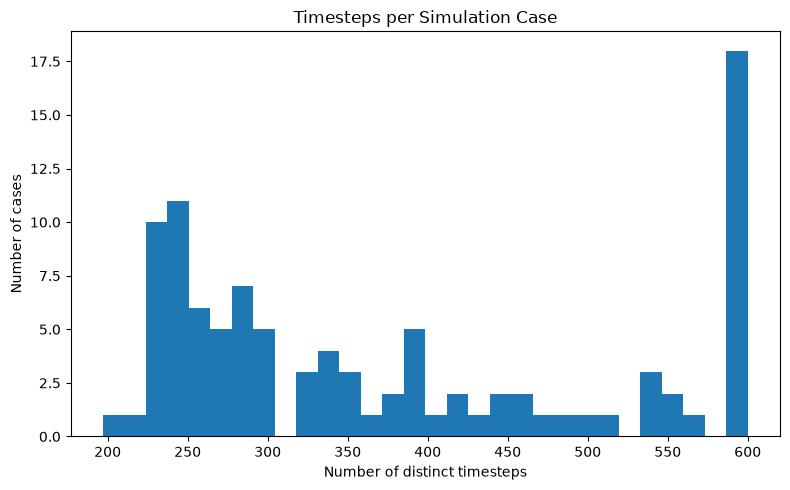

In [15]:
steps_per_case = df.groupby("case_id")["step"].nunique()
print(steps_per_case.describe())

plt.figure(figsize=(8, 5))
plt.hist(steps_per_case, bins=30)
plt.xlabel("Number of distinct timesteps")
plt.ylabel("Number of cases")
plt.title("Timesteps per Simulation Case")
plt.tight_layout()
plt.show()

## 16. Target class counts

In [16]:
print(df["is_critical"].value_counts())

is_critical
False    1000921
True      638245
Name: count, dtype: int64


## 17. Target class percentages

In [17]:
counts = df["is_critical"].value_counts()
percent = df["is_critical"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percentage": percent}))

               count  percentage
is_critical                     
False        1000921     61.0628
True          638245     38.9372


## 18. Plot target class distribution

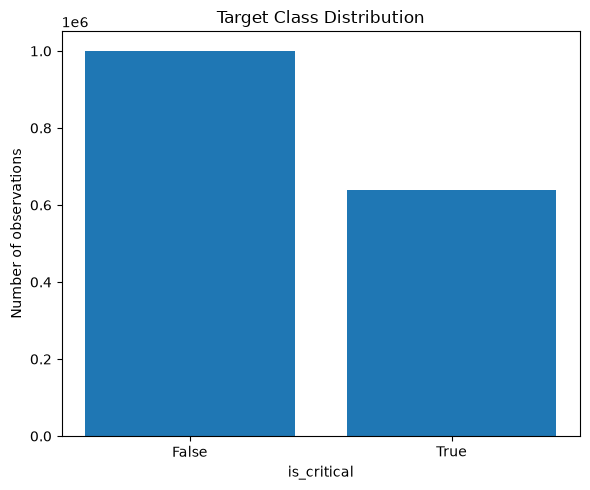

In [18]:
counts = df["is_critical"].value_counts().sort_index()

plt.figure(figsize=(6, 5))
plt.bar(counts.index.astype(str), counts.values)
plt.xlabel("is_critical")
plt.ylabel("Number of observations")
plt.title("Target Class Distribution")
plt.tight_layout()
plt.show()

## 19. Agent-level target labels

In [19]:
# does the label of an agent ever change during a simulation?
label_changes = df.groupby(["case_id", "agent_id"])["is_critical"].nunique()
print("Agents whose is_critical label changes:", (label_changes > 1).sum())

agent_labels = df.groupby(["case_id", "agent_id"])["is_critical"].first()
print(agent_labels.value_counts())

Agents whose is_critical label changes: 85
is_critical
False    2791
True     1693
Name: count, dtype: int64


## 20. Critical fraction over simulation time

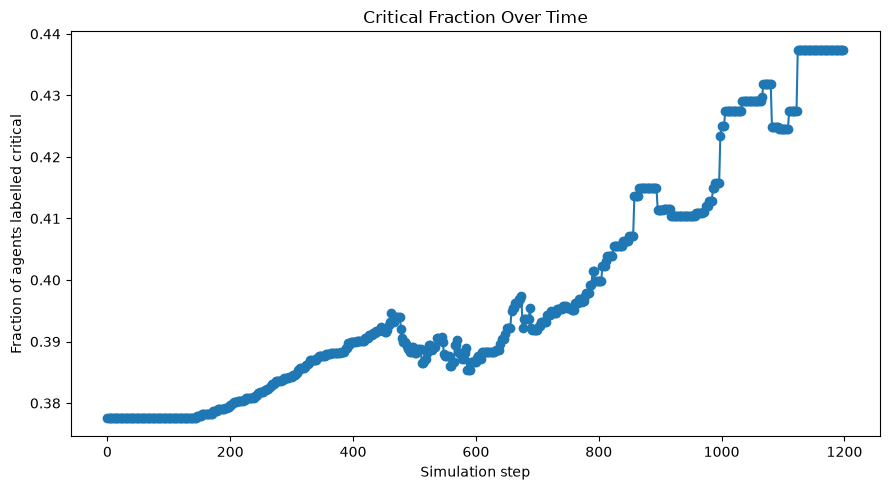

In [20]:
critical_by_step = df.groupby("step")["is_critical"].mean()

plt.figure(figsize=(9, 5))
plt.plot(critical_by_step.index, critical_by_step.values, marker="o")
plt.xlabel("Simulation step")
plt.ylabel("Fraction of agents labelled critical")
plt.title("Critical Fraction Over Time")
plt.tight_layout()
plt.show()

## 21. Investigate was_promoted: overall counts and cross-tab

In [21]:
print("was_promoted counts:")
print(df["was_promoted"].value_counts())

print("\nwas_promoted vs is_critical (counts):")
print(pd.crosstab(df["was_promoted"], df["is_critical"]))

print("\nwas_promoted vs is_critical (row percentages):")
print(pd.crosstab(df["was_promoted"], df["is_critical"], normalize="index"))

was_promoted counts:
was_promoted
False    1624684
True       14482
Name: count, dtype: int64

was_promoted vs is_critical (counts):
is_critical     False   True 
was_promoted                 
False         1000921  623763
True                0   14482

was_promoted vs is_critical (row percentages):
is_critical   False  True 
was_promoted              
False        0.6161 0.3839
True         0.0000 1.0000


## 22. was_promoted by timestep

In [22]:
promotion_by_step = df.groupby("step").agg(
    total_observations=("was_promoted", "size"),
    promoted_observations=("was_promoted", "sum"),
    promotion_rate=("was_promoted", "mean"),
)
promotion_by_step

,total_observations,promoted_observations,promotion_rate
step,,,
0,4484,0,0.0000
2,4484,0,0.0000
4,4484,0,0.0000
6,4484,0,0.0000
8,4484,0,0.0000
...,...,...,...
1190,775,21,0.0271
1192,775,21,0.0271
1194,775,21,0.0271


## 23. Plot promoted observations over time

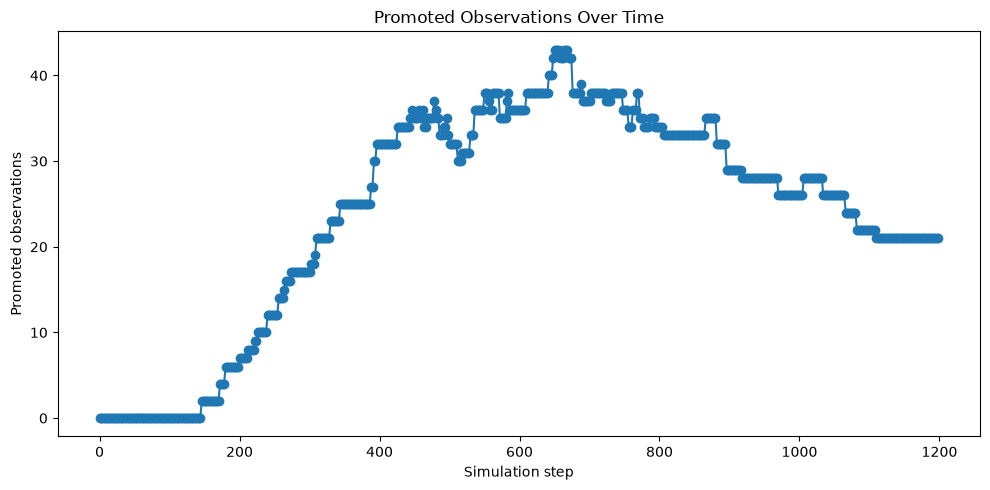

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(promotion_by_step.index, promotion_by_step["promoted_observations"], marker="o")
plt.xlabel("Simulation step")
plt.ylabel("Promoted observations")
plt.title("Promoted Observations Over Time")
plt.tight_layout()
plt.show()

## 24. Plot promotion rate over time

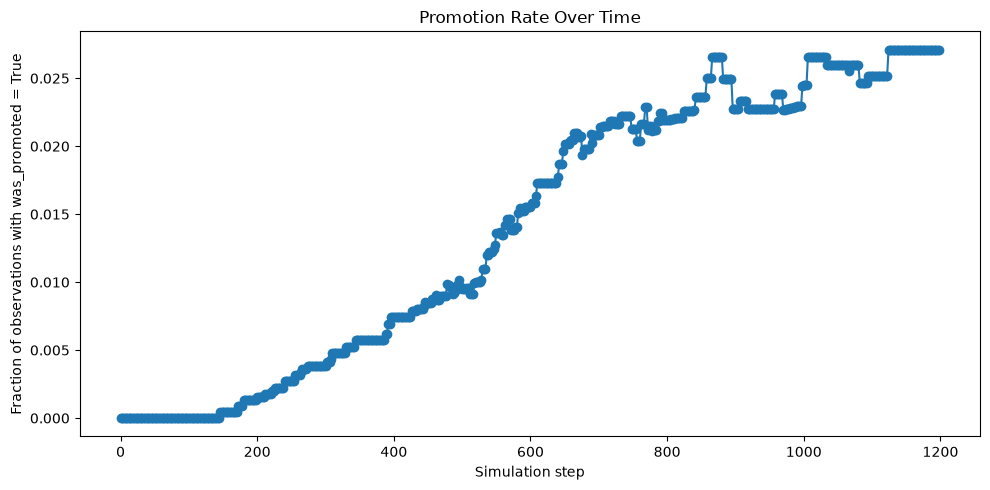

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(promotion_by_step.index, promotion_by_step["promotion_rate"], marker="o")
plt.xlabel("Simulation step")
plt.ylabel("Fraction of observations with was_promoted = True")
plt.title("Promotion Rate Over Time")
plt.tight_layout()
plt.show()

## 25. Promotion history per agent

In [25]:
df_sorted = df.sort_values(["case_id", "agent_id", "step"])

promotion_history = df_sorted.groupby(["case_id", "agent_id"]).agg(
    first_step=("step", "first"),
    last_step=("step", "last"),
    ever_promoted=("was_promoted", "max"),
    promoted_observations=("was_promoted", "sum"),
    n_observations=("was_promoted", "size"),
)
promotion_history.head(20)

first_step  last_step  ever_promoted  \
case_id       agent_id                                         
c001_n60_none 0                  0        432          False   
              1                  0        432          False   
              2                  0        432          False   
              3                  0        432          False   
              4                  0        432          False   
              5                  0        432          False   
              6                  0        432          False   
              7                  0        432          False   
              8                  0        432          False   
              9                  0        432          False   
              10                 0        432          False   
              11                 0        432          False   
              12                 0        432          False   
              13                 0        432          False   
              14                 0        432          False   
              15                 0        432          False   
              16                 0        432          False   
              17                 0        432          False   
              18                 0        432          False   
              19                 0        432          False   

                        promoted_observations  n_observations  
case_id       agent_id                                         
c001_n60_none 0                             0             217  
              1                             0             217  
              2                             0             217  
              3                             0             217  
              4                             0             217  
              5                             0             217  
              6                             0             217  
              7                             0             217  
              8                             0             217  
              9                             0             217  
              10                            0             217  
              11                            0             217  
              12                            0             217  
              13                            0             217  
              14                            0             217  
              15                            0             217  
              16                            0             217  
              17                            0             217  
              18                            0             217  
              19                            0             217

## 26. First promotion step per agent

In [26]:
promoted_rows = df[df["was_promoted"] == True]
first_promotion = promoted_rows.groupby(["case_id", "agent_id"])["step"].min()

print("Number of unique agents ever promoted:", len(first_promotion))
print(first_promotion.describe())
first_promotion.head(20)

Number of unique agents ever promoted: 85
count     85.0000
mean     480.5176
std      196.8050
min      146.0000
25%      330.0000
50%      478.0000
75%      584.0000
max     1006.0000
Name: step, dtype: float64


case_id          agent_id
c003_n37_medium  15          642
                 36          642
c004_n30_heavy   18          308
c005_n52_heavy   13          264
                 25          530
                 45          530
c007_n75_light   67          212
c012_n18_heavy   15          786
c015_n75_medium  53          562
                 69          562
c017_n75_heavy   36          388
                 53          388
                 58          866
                 65          866
c018_n37_heavy   12          172
                 14          172
c019_n68_medium  22          478
                 64          478
c021_n24_heavy   6           302
                 20          462
Name: step, dtype: int64

## 27. Test whether promotion persists after becoming True

In [ ]:
# once an agent is promoted, does was_promoted stay True?
df_sorted = df.sort_values(["case_id", "agent_id", "step"]).copy()
df_sorted["was_promoted"] = df_sorted["was_promoted"].astype(bool)
df_sorted["promoted_so_far"] = df_sorted.groupby(["case_id", "agent_id"])["was_promoted"].cummax()
df_sorted["lost_promotion"] = df_sorted["promoted_so_far"] & ~df_sorted["was_promoted"]

lost = df_sorted.groupby(["case_id", "agent_id"])["lost_promotion"].any()
print("Agents with persistent promotion:", (~lost).sum())
print("Agents with non-persistent promotion:", lost.sum())

Agents with persistent promotion: 4484
Agents with non-persistent promotion: 0


## 28. Find False-to-True promotion transitions

In [28]:
temp = df.sort_values(["case_id", "agent_id", "step"]).copy()
temp["previous_promoted"] = temp.groupby(["case_id", "agent_id"])["was_promoted"].shift(1)

promotions = temp[(temp["was_promoted"] == True) & (temp["previous_promoted"] == False)]
print("Observed False-to-True transitions:", len(promotions))

promotions[["case_id", "agent_id", "step", "is_critical", "criticality_score",
            "num_neighbors", "degree_centrality", "betweenness_centrality"]].head(30)

Observed False-to-True transitions: 85


,case_id,agent_id,step,is_critical,criticality_score,num_neighbors,degree_centrality,betweenness_centrality
40883,c003_n37_medium,15,642,True,0.6175,0,0.0000,0.0000
40899,c003_n37_medium,36,642,True,0.7689,28,0.9394,0.0001
50246,c004_n30_heavy,18,308,True,0.5665,21,0.8400,0.0051
60313,c005_n52_heavy,13,264,True,0.6031,2,0.0417,0.0000
66836,c005_n52_heavy,25,530,True,0.8530,20,0.4375,0.0089
66855,c005_n52_heavy,45,530,True,0.5686,39,0.8750,0.0002
96157,c007_n75_light,67,212,True,0.7900,16,0.2222,0.0045
160793,c012_n18_heavy,15,786,True,0.6714,4,0.6923,0.0000
202959,c015_n75_medium,53,562,True,0.6155,2,0.0417,0.0002
202975,c015_n75_medium,69,562,True,0.6191,2,0.0417,0.0002


## 29. Count unique agents ever promoted

In [29]:
ever_promoted = df.groupby(["case_id", "agent_id"])["was_promoted"].max().astype(bool)

print("Total unique case-agent identities:", len(ever_promoted))
print("Agents ever promoted:", ever_promoted.sum())
print("Agents never promoted:", (~ever_promoted).sum())

Total unique case-agent identities: 4484
Agents ever promoted: 85
Agents never promoted: 4399


## 30. Agent-level promotion versus criticality

In [30]:
agent_level = df.groupby(["case_id", "agent_id"]).agg(
    is_critical=("is_critical", "first"),
    was_promoted=("was_promoted", "max"),
)
pd.crosstab(agent_level["was_promoted"], agent_level["is_critical"])

is_critical,False,True
was_promoted,,
False,2706,1693
True,85,0


## 31. Numerical feature summary

In [31]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
num_agents,1639166.0000,54.3114,18.4762,18.0000,37.0000,60.0000,75.0000,75.0000
n_obstacles,1639166.0000,4.9259,3.4338,0.0000,2.0000,5.0000,7.0000,12.0000
obstacle_density,1639166.0000,0.1068,0.0991,0.0000,0.0373,0.0893,0.1427,0.6415
mean_obstacle_size,1639166.0000,14.0799,6.4911,0.0000,9.5880,13.8655,18.0581,32.0000
clutter_index,1639166.0000,0.6008,0.2978,0.0000,0.3517,0.7333,0.8000,1.0000
obstacle_clustering,1639166.0000,0.5255,0.2502,0.0403,0.3415,0.5253,0.7300,0.9979
step,1639166.0000,419.0570,295.3060,0.0000,182.0000,368.0000,596.0000,1198.0000
agent_id,1639166.0000,26.6057,18.9669,0.0000,11.0000,23.0000,40.0000,74.0000
rel_x,1639166.0000,0.0000,20.0389,-131.2023,-11.4935,-0.0557,11.1999,129.1866
rel_y,1639166.0000,-0.0000,22.6908,-144.6859,-12.5446,3.0877,14.4421,118.3654


## 32. Numeric ranges

In [32]:
range_table = pd.DataFrame({
    "min": df[numeric_cols].min(),
    "max": df[numeric_cols].max(),
    "mean": df[numeric_cols].mean(),
    "std": df[numeric_cols].std(),
})
range_table

,min,max,mean,std
num_agents,18.0000,75.0000,54.3114,18.4762
n_obstacles,0.0000,12.0000,4.9259,3.4338
obstacle_density,0.0000,0.6415,0.1068,0.0991
mean_obstacle_size,0.0000,32.0000,14.0799,6.4911
clutter_index,0.0000,1.0000,0.6008,0.2978
obstacle_clustering,0.0403,0.9979,0.5255,0.2502
step,0.0000,1198.0000,419.0570,295.3060
agent_id,0.0000,74.0000,26.6057,18.9669
rel_x,-131.2023,129.1866,0.0000,20.0389
rel_y,-144.6859,118.3654,-0.0000,22.6908


## 33. Basic physical/logical validity checks

In [ ]:
checks = {}

# these should never be negative
for col in ["speed", "num_neighbors", "mean_neighbor_dist", "min_neighbor_dist",
            "n_obstacles", "num_agents"]:
    checks[col + " < 0"] = (df[col] < 0).sum()

# these should stay between 0 and 1
for col in ["rank_dist_to_centroid", "rank_dist_to_target", "criticality_score",
            "angular_coverage", "obstacle_density"]:
    checks[col + " outside [0, 1]"] = ((df[col] < 0) | (df[col] > 1)).sum()

pd.Series(checks, name="rows_flagged").to_frame()

,rows_flagged
speed < 0,0
num_neighbors < 0,0
mean_neighbor_dist < 0,0
min_neighbor_dist < 0,0
n_obstacles < 0,0
num_agents < 0,0
"rank_dist_to_centroid outside [0, 1]",0
"rank_dist_to_target outside [0, 1]",0
"criticality_score outside [0, 1]",0
"angular_coverage outside [0, 1]",0


## 34. Plot distributions of selected numerical features

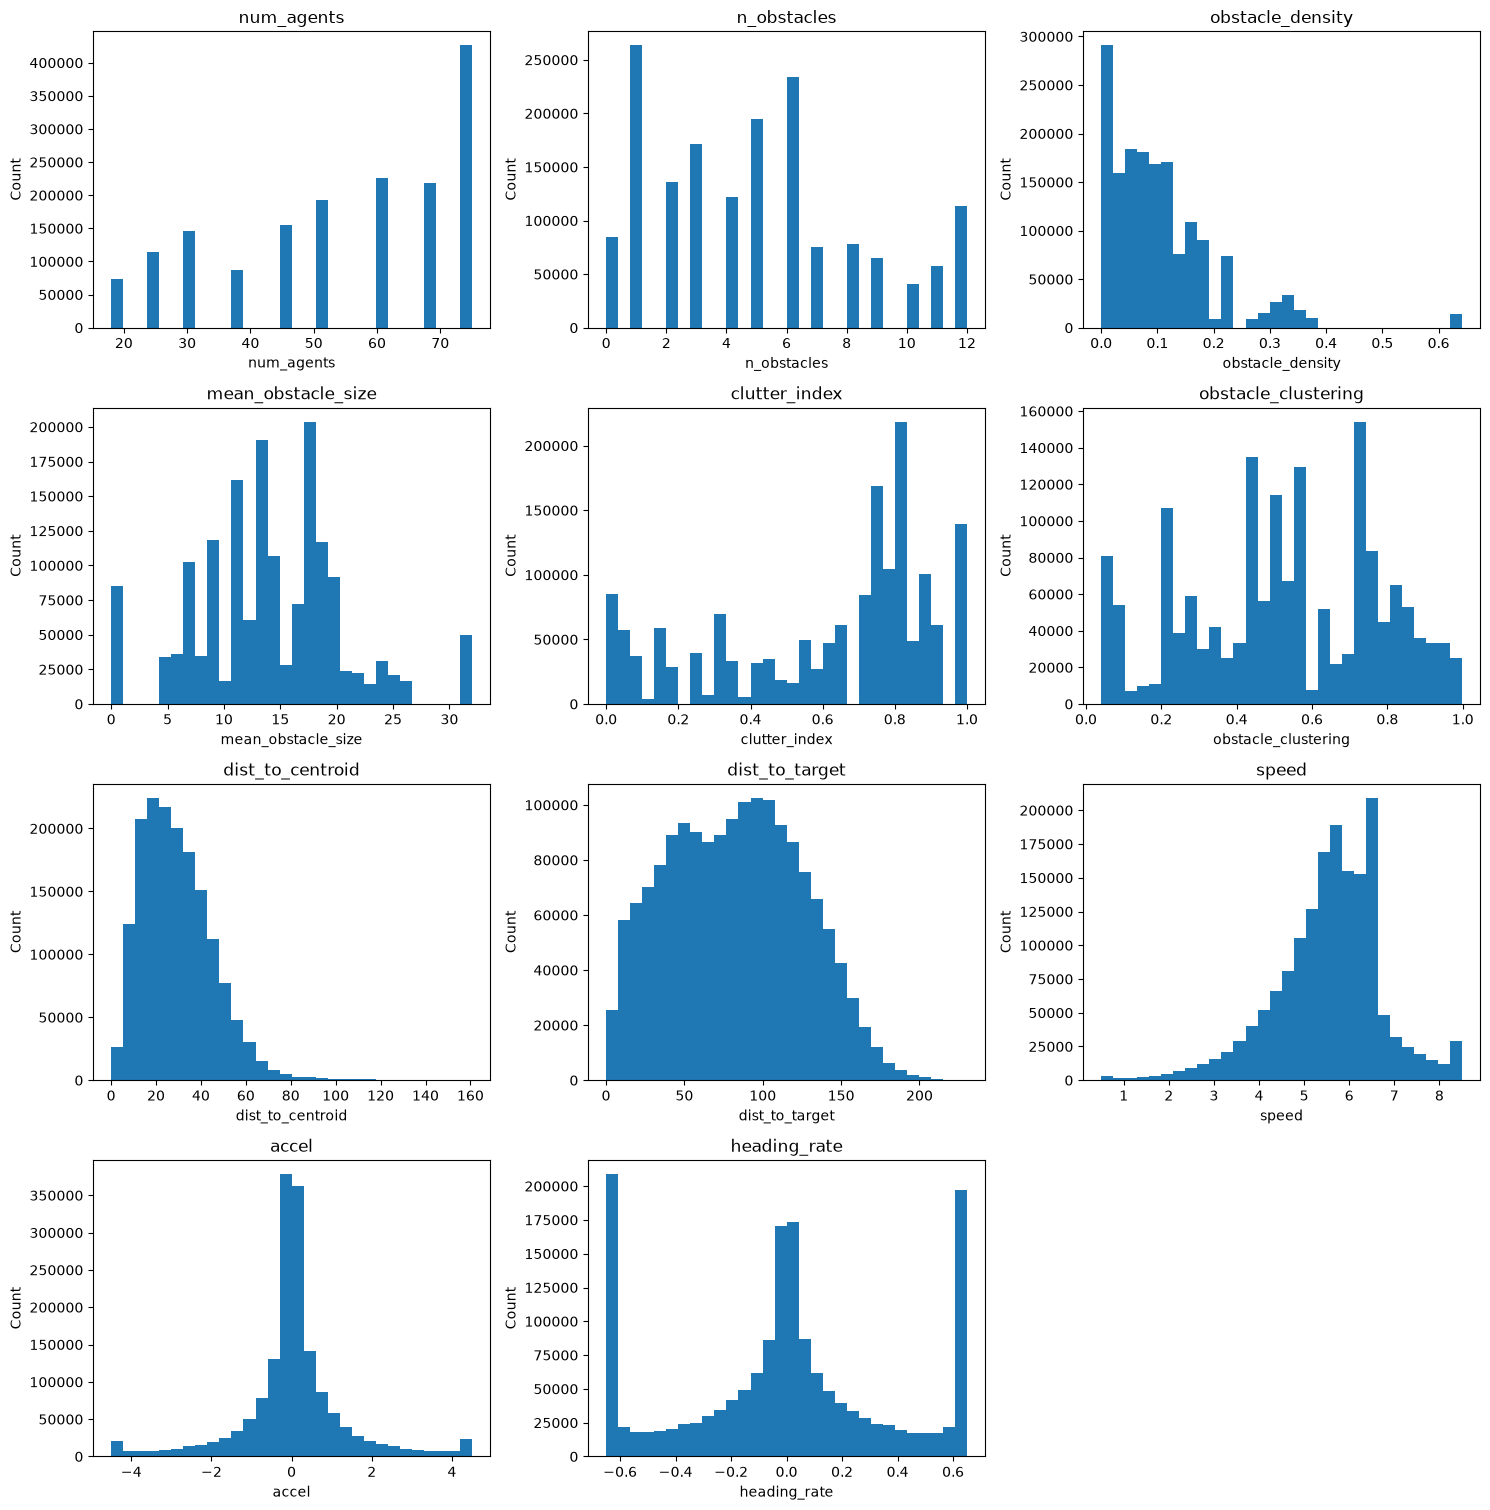

In [53]:
cols_to_plot = ["num_agents", "n_obstacles", "obstacle_density", "mean_obstacle_size",
                "clutter_index", "obstacle_clustering", "dist_to_centroid",
                "dist_to_target", "speed", "accel", "heading_rate"]

n_cols = 3
n_rows = int(np.ceil(len(cols_to_plot) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.8 * n_rows))
axes = axes.flatten()

for i in range(len(cols_to_plot)):
    col = cols_to_plot[i]
    axes[i].hist(df[col].dropna(), bins=30)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

for j in range(len(cols_to_plot), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## 35. Compare a feature distribution for critical and decoy observations

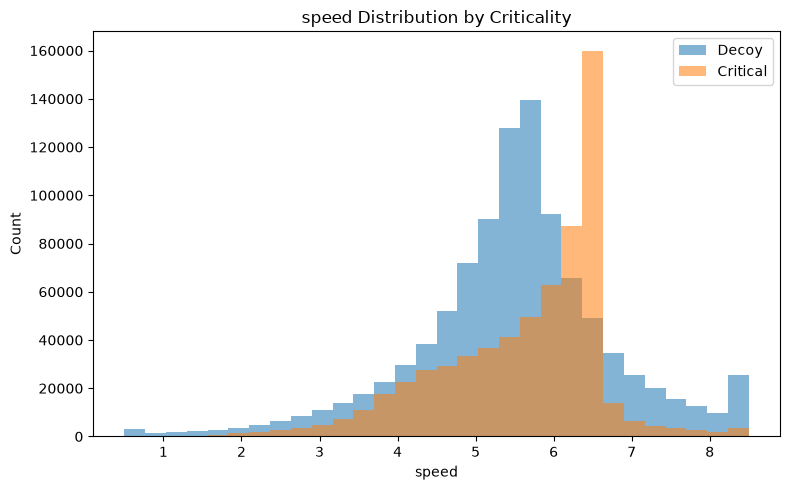

In [35]:
col = "speed"
decoy = df[df["is_critical"] == 0][col]
critical = df[df["is_critical"] == 1][col]

plt.figure(figsize=(8, 5))
plt.hist(decoy, bins=30, alpha=0.55, label="Decoy")
plt.hist(critical, bins=30, alpha=0.55, label="Critical")
plt.xlabel(col)
plt.ylabel("Count")
plt.title(col + " Distribution by Criticality")
plt.legend()
plt.tight_layout()
plt.show()

## 36. Boxplots by target

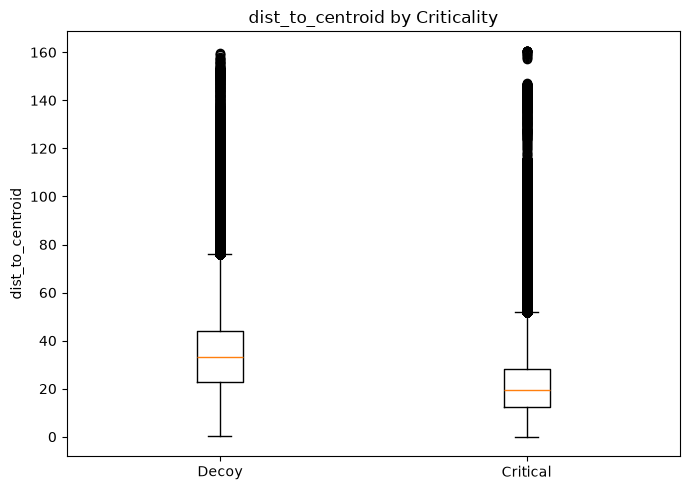

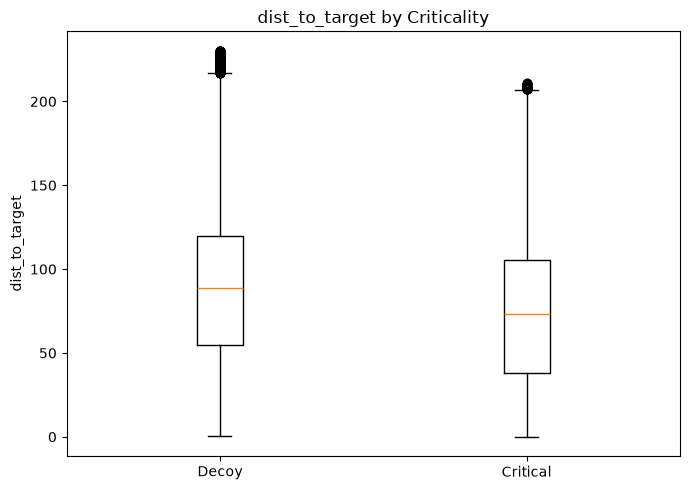

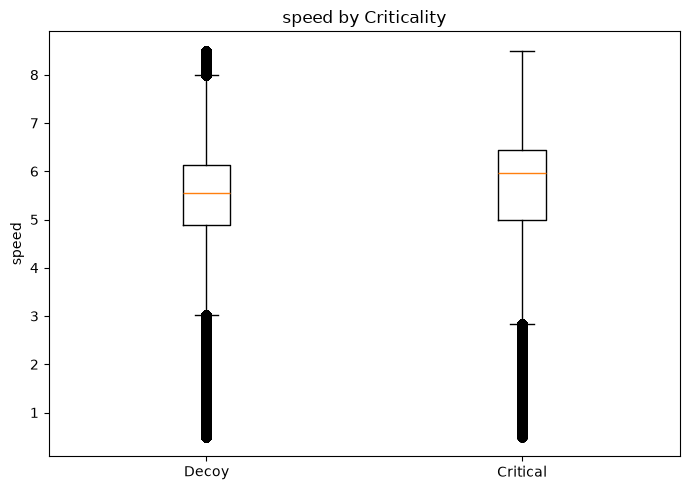

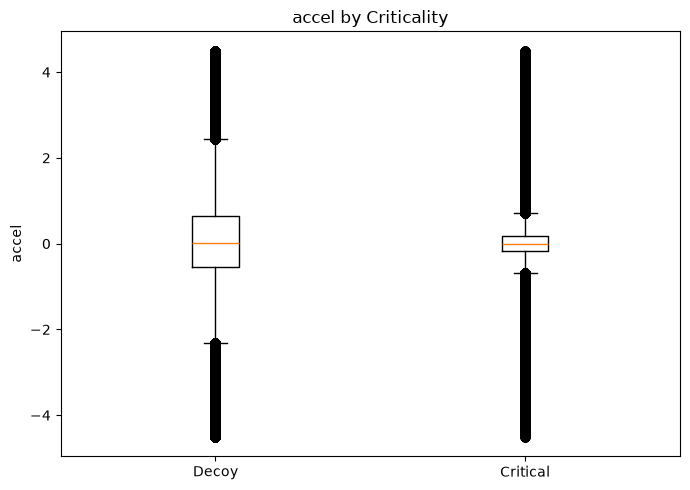

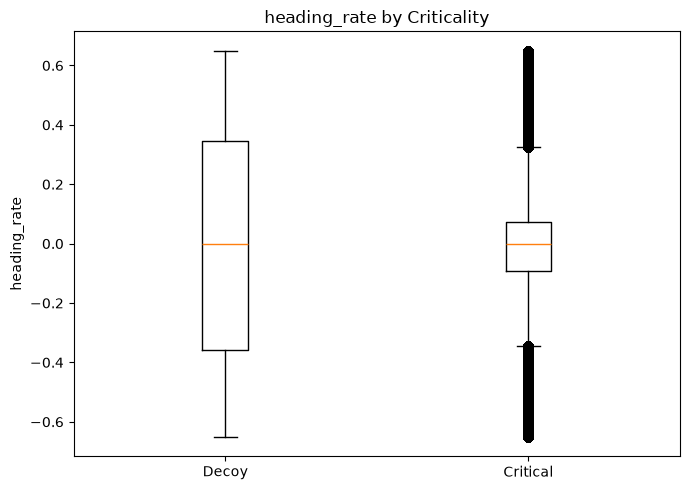

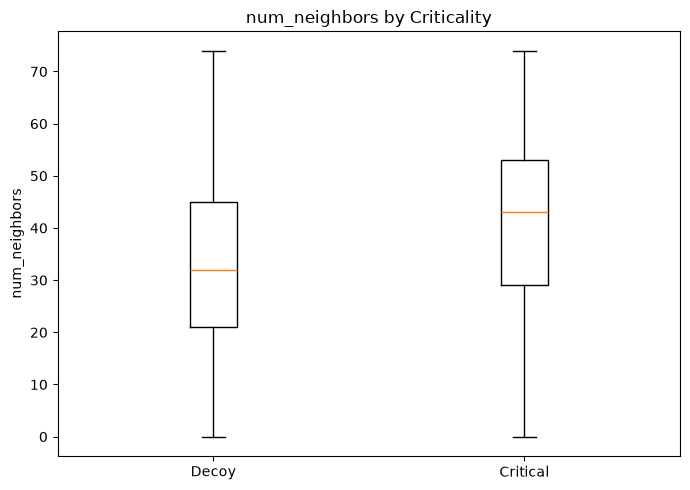

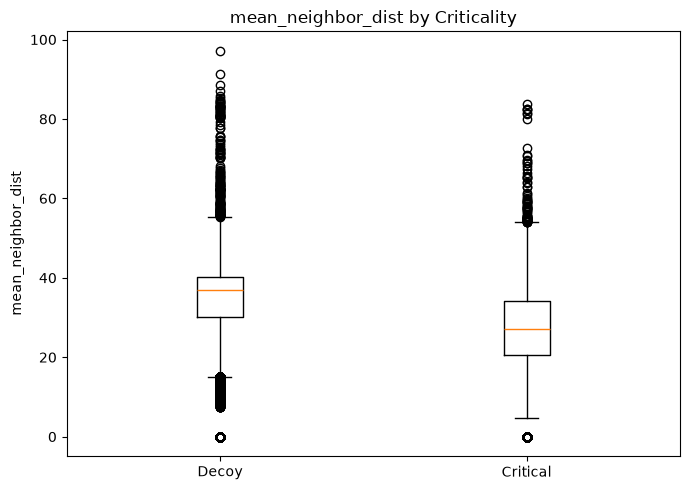

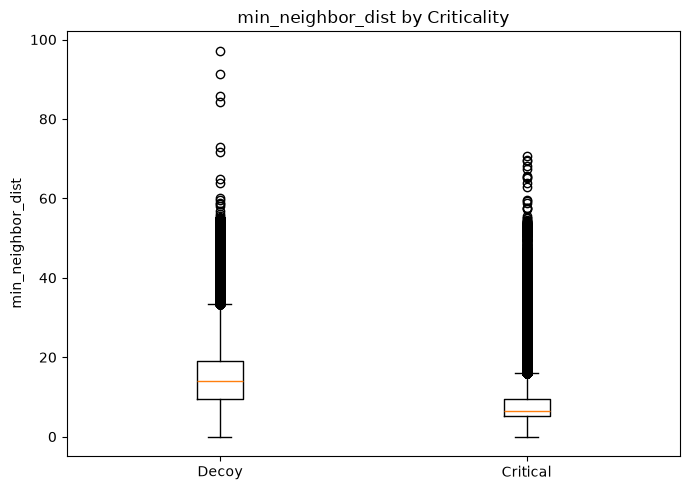

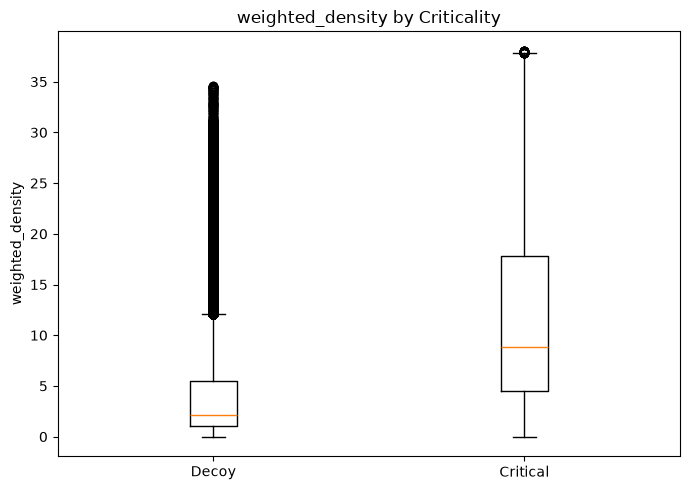

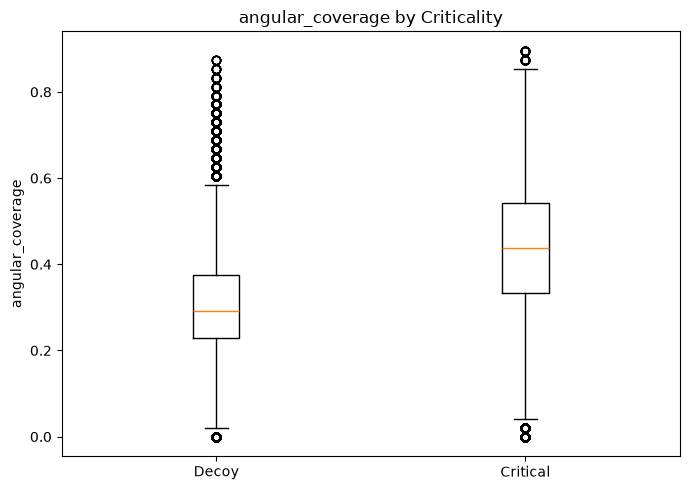

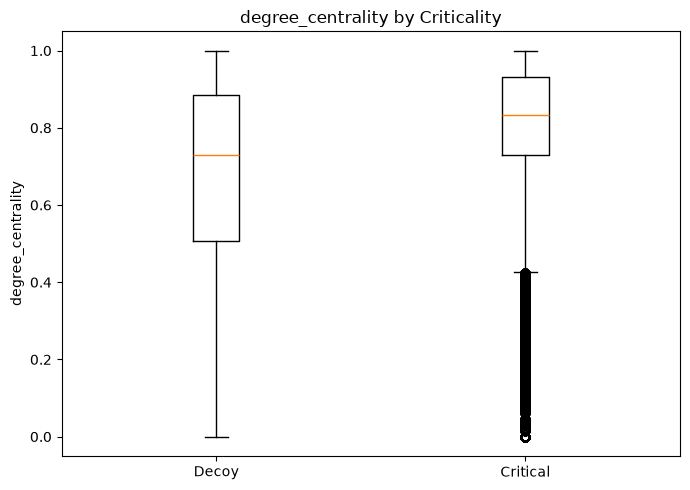

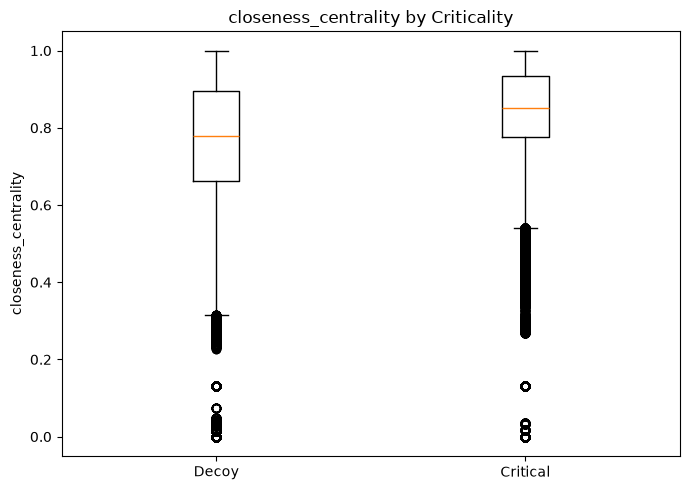

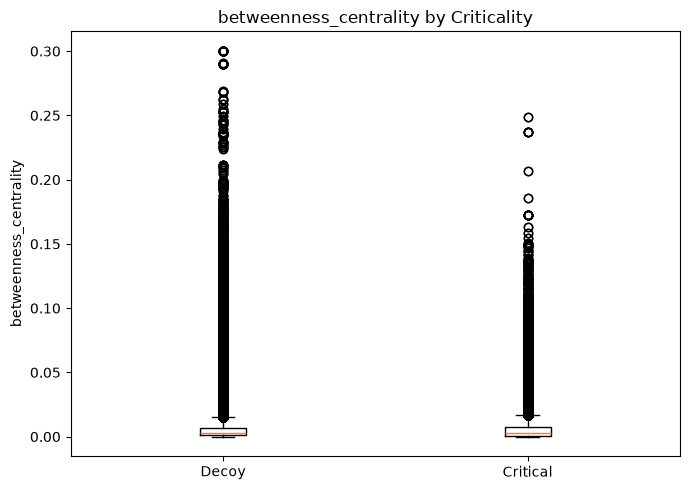

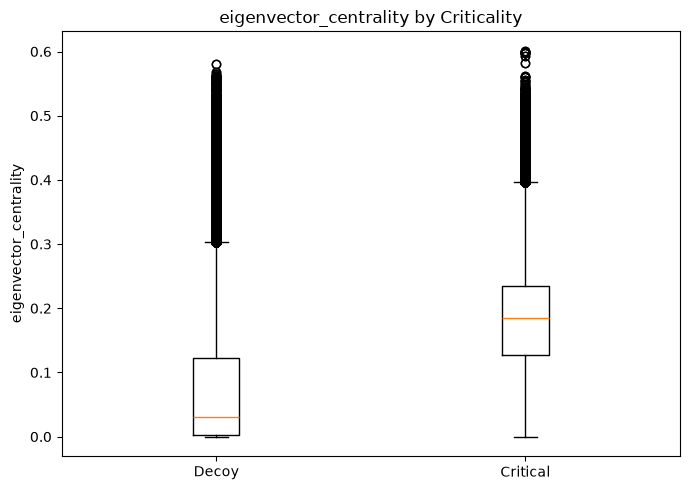

In [36]:
important_features = ["dist_to_centroid", "dist_to_target", "speed", "accel", "heading_rate",
                      "num_neighbors", "mean_neighbor_dist", "min_neighbor_dist",
                      "weighted_density", "angular_coverage", "degree_centrality",
                      "closeness_centrality", "betweenness_centrality", "eigenvector_centrality"]

for col in important_features:
    decoy = df[df["is_critical"] == 0][col].dropna()
    critical = df[df["is_critical"] == 1][col].dropna()

    plt.figure(figsize=(7, 5))
    plt.boxplot([decoy, critical])
    plt.xticks([1, 2], ["Decoy", "Critical"])
    plt.ylabel(col)
    plt.title(col + " by Criticality")
    plt.tight_layout()
    plt.show()

## 37. Class-wise numerical summary

In [37]:
df.groupby("is_critical")[numeric_cols].agg(["mean", "median", "std"]).T

is_critical                      False    True 
num_agents             mean    54.2151  54.4624
                       median  60.0000  60.0000
                       std     18.4257  18.5542
n_obstacles            mean     4.9225   4.9311
                       median   5.0000   5.0000
                       std      3.4020   3.4831
obstacle_density       mean     0.1064   0.1074
                       median   0.0893   0.0893
                       std      0.0979   0.1008
mean_obstacle_size     mean    14.1090  14.0343
                       median  13.8655  13.8082
                       std      6.4199   6.6010
clutter_index          mean     0.6025   0.5982
                       median   0.7333   0.7333
                       std      0.2952   0.3019
obstacle_clustering    mean     0.5204   0.5335
                       median   0.5228   0.5253
                       std      0.2484   0.2529
step                   mean   413.0463 428.4831
                       median 362.0000 376.0000
                       std    292.1690 299.9173
agent_id               mean    26.2968  27.0902
                       median  22.0000  24.0000
                       std     18.8574  19.1272
rel_x                  mean     0.4019  -0.6303
                       median   0.4301  -0.5241
                       std     22.7656  14.7604
rel_y                  mean    -4.8382   7.5875
                       median  -2.4109   7.6579
                       std     24.9777  15.7998
rel_z                  mean     1.0258  -1.6087
                       median   0.4657  -1.7862
                       std     16.7467   9.3946
dist_to_centroid       mean    34.5661  21.5314
                       median  33.2501  19.4533
                       std     15.8875  12.3579
rank_dist_to_centroid  mean     0.6123   0.3239
                       median   0.6486   0.2712
                       std      0.2669   0.2485
dist_to_target         mean    88.3334  73.4901
                       median  88.4888  73.3096
                       std     41.4653  42.4722
rank_dist_to_target    mean     0.5726   0.3861
                       median   0.6275   0.3651
                       std      0.3042   0.2404
vx                     mean    -0.2585  -0.3738
                       median  -0.3057  -0.4130
                       std      3.3654   3.3092
vy                     mean     2.8541   3.2809
                       median   3.8632   4.3487
                       std      3.1150   3.1186
vz                     mean    -0.0624  -0.0976
                       median  -0.0553  -0.0705
                       std      1.5786   1.1923
speed                  mean     5.4908   5.6466
                       median   5.5486   5.9563
                       std      1.2604   1.0618
heading                mean     1.0175   1.0818
                       median   1.3945   1.4519
                       std      1.5041   1.4778
flight_path_angle      mean    -0.0122  -0.0199
                       median  -0.0103  -0.0123
                       std      0.2966   0.2302
accel                  mean     0.0574  -0.0026
                       median   0.0223  -0.0045
                       std      1.6053   0.6774
heading_rate           mean    -0.0037  -0.0113
                       median  -0.0021  -0.0013
                       std      0.4383   0.2893
num_neighbors          mean    33.3192  40.7838
                       median  32.0000  43.0000
                       std     15.0875  14.9596
mean_neighbor_dist     mean    34.6293  27.0316
                       median  36.8820  27.2310
                       std      7.8373   7.9537
min_neighbor_dist      mean    14.6961   7.6245
                       median  14.1232   6.3510
                       std      6.4357   3.8799
weighted_density       mean     4.4225  11.6570
                       median   2.1778   8.8144
                       std      5.2670   8.7819
angular_coverage       mean     0.3104   0.4381
                

## 38. Class-wise feature means

In [38]:
comparison = df.groupby("is_critical")[numeric_cols].mean().T
comparison.columns = ["Decoy_mean", "Critical_mean"]
comparison

,Decoy_mean,Critical_mean
num_agents,54.2151,54.4624
n_obstacles,4.9225,4.9311
obstacle_density,0.1064,0.1074
mean_obstacle_size,14.1090,14.0343
clutter_index,0.6025,0.5982
obstacle_clustering,0.5204,0.5335
step,413.0463,428.4831
agent_id,26.2968,27.0902
rel_x,0.4019,-0.6303
rel_y,-4.8382,7.5875


## 39. Correlation matrix (excluding outcome columns)

In [39]:
corr_cols = [c for c in numeric_cols if c != "is_critical" and c != "was_promoted"]
corr = df[corr_cols].corr()
corr

,num_agents,n_obstacles,obstacle_density,mean_obstacle_size,clutter_index,obstacle_clustering,step,agent_id,rel_x,rel_y,rel_z,dist_to_centroid,rank_dist_to_centroid,dist_to_target,rank_dist_to_target,vx,vy,vz,speed,heading,flight_path_angle,accel,heading_rate,num_neighbors,mean_neighbor_dist,min_neighbor_dist,weighted_density,angular_coverage,criticality_score,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality
num_agents,1.0000,0.0847,-0.0726,0.0943,0.1578,0.1127,0.0521,0.4873,-0.0000,0.0000,-0.0000,0.2320,-0.0000,0.0382,0.0000,-0.0583,-0.0637,-0.0338,-0.0268,-0.0373,-0.0317,0.0094,0.0072,0.6477,0.1802,-0.0232,0.2146,0.4395,-0.0328,-0.3622,-0.3954,-0.0138,-0.3199
n_obstacles,0.0847,1.0000,0.5991,-0.0049,0.8193,-0.1119,0.1228,0.0428,0.0000,0.0000,0.0000,-0.0073,-0.0000,0.0744,0.0000,-0.0622,-0.0934,0.0176,-0.0309,-0.0127,0.0124,0.0056,0.0142,0.0890,-0.0763,-0.0605,0.1384,0.0239,0.0195,-0.0036,-0.0310,0.0089,-0.0148
obstacle_density,-0.0726,0.5991,1.0000,0.5179,0.7021,-0.0736,0.1419,-0.0339,0.0000,-0.0000,0.0000,-0.0119,-0.0000,0.0649,-0.0000,-0.0309,-0.0659,0.0219,-0.0230,-0.0390,0.0175,0.0079,0.0029,-0.0561,-0.1130,-0.0751,0.0697,-0.0806,0.0094,0.0028,-0.0298,0.0483,0.0256
mean_obstacle_size,0.0943,-0.0049,0.5179,1.0000,0.4472,0.0824,0.1087,0.0461,-0.0000,-0.0000,0.0000,0.0575,0.0000,0.0257,0.0000,-0.0648,-0.0654,0.0388,-0.0295,-0.0463,0.0361,0.0050,-0.0006,0.0035,-0.0213,-0.0315,0.0298,-0.0115,-0.0136,-0.0943,-0.1144,0.0501,-0.0393
clutter_index,0.1578,0.8193,0.7021,0.4472,1.0000,-0.0839,0.1693,0.0780,0.0000,-0.0000,0.0000,0.0308,-0.0000,0.0668,0.0000,-0.0778,-0.1287,0.0298,-0.0437,-0.0399,0.0259,0.0078,0.0102,0.1039,-0.0595,-0.0659,0.1381,0.0357,0.0015,-0.0669,-0.0973,0.0302,-0.0519
obstacle_clustering,0.1127,-0.1119,-0.0736,0.0824,-0.0839,1.0000,-0.0186,0.0551,-0.0000,0.0000,0.0000,0.0080,0.0000,0.0327,-0.0000,-0.0270,-0.0107,-0.0121,0.0189,0.0091,-0.0119,0.0024,0.0117,0.0694,-0.0440,-0.0272,0.0669,0.0408,0.0103,-0.0169,-0.0288,-0.0096,-0.0147
step,0.0521,0.1228,0.1419,0.1087,0.1693,-0.0186,1.0000,0.0231,0.0000,-0.0000,-0.0000,-0.1992,-0.0000,-0.5244,0.0000,-0.0167,-0.2653,0.1129,-0.0416,-0.1773,0.1049,-0.0184,-0.0380,0.0888,-0.4796,-0.2248,0.4671,-0.0168,0.0918,0.1595,0.1429,-0.0978,0.0598
agent_id,0.4873,0.0428,-0.0339,0.0461,0.0780,0.0551,0.0231,1.0000,-0.0006,-0.0101,-0.0055,0.1943,0.0813,0.0294,0.0113,-0.0245,-0.0368,-0.0087,-0.0301,-0.0165,-0.0084,0.0019,0.0049,0.2489,0.1374,0.0387,0.0619,0.1459,-0.0025,-0.2517,-0.2609,-0.0538,-0.1911
rel_x,-0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0006,1.0000,0.0006,-0.0054,0.0372,0.0109,0.0333,0.0637,0.0168,0.0022,0.0069,0.0000,0.0048,0.0079,0.0037,0.0905,-0.0272,0.0202,0.0110,-0.0409,-0.0216,-0.0107,-0.0221,-0.0217,0.0080,-0.0404
rel_y,0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0101,0.0006,1.0000,0.0003,-0.2988,-0.2444,-0.4199,-0.7361,-0.0025,0.0415,-0.0387,0.0188,0.0430,-0.0419,-0.0338,0.0068,0.2248,-0.2746,-0.3296,0.2584,0.1990,0.1792,0.2781,0.2300,-0.1043,0.3327


## 40. Plot correlation matrix

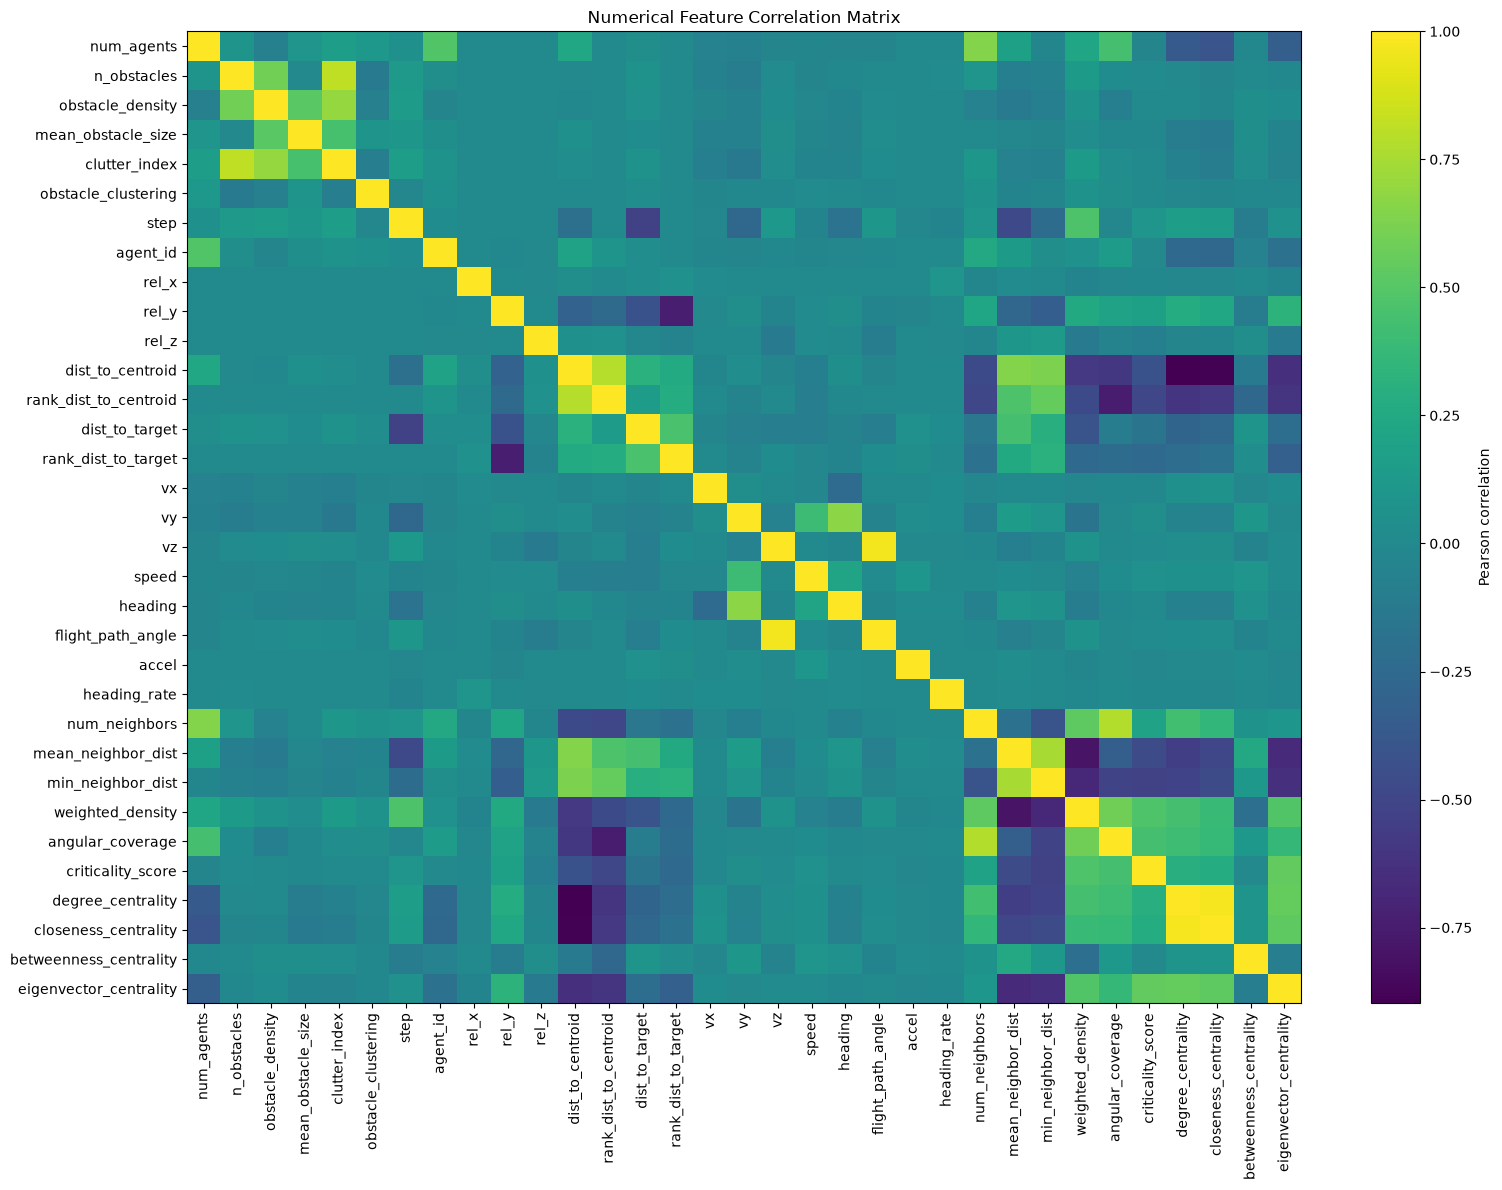

In [40]:
plt.figure(figsize=(16, 12))
plt.imshow(corr, aspect="auto", interpolation="nearest")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.colorbar(label="Pearson correlation")
plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 41. Check whether speed is derived from velocity

In [41]:
calculated_speed = np.sqrt(df["vx"] ** 2 + df["vy"] ** 2 + df["vz"] ** 2)
difference = (calculated_speed - df["speed"]).abs()

print("Maximum absolute speed difference:", difference.max())
print("Mean absolute speed difference:", difference.mean())

Maximum absolute speed difference: 3.552713678800501e-15
Mean absolute speed difference: 2.9468430878125087e-16


## 42. Check whether distance is derived from relative coordinates

In [42]:
calculated_dist = np.sqrt(df["rel_x"] ** 2 + df["rel_y"] ** 2 + df["rel_z"] ** 2)
difference = (calculated_dist - df["dist_to_centroid"]).abs()

print("Maximum absolute distance difference:", difference.max())
print("Mean absolute distance difference:", difference.mean())

Maximum absolute distance difference: 5.684341886080802e-14
Mean absolute distance difference: 7.364300313174544e-16


## 43. Local swarm geometry distributions and target comparisons

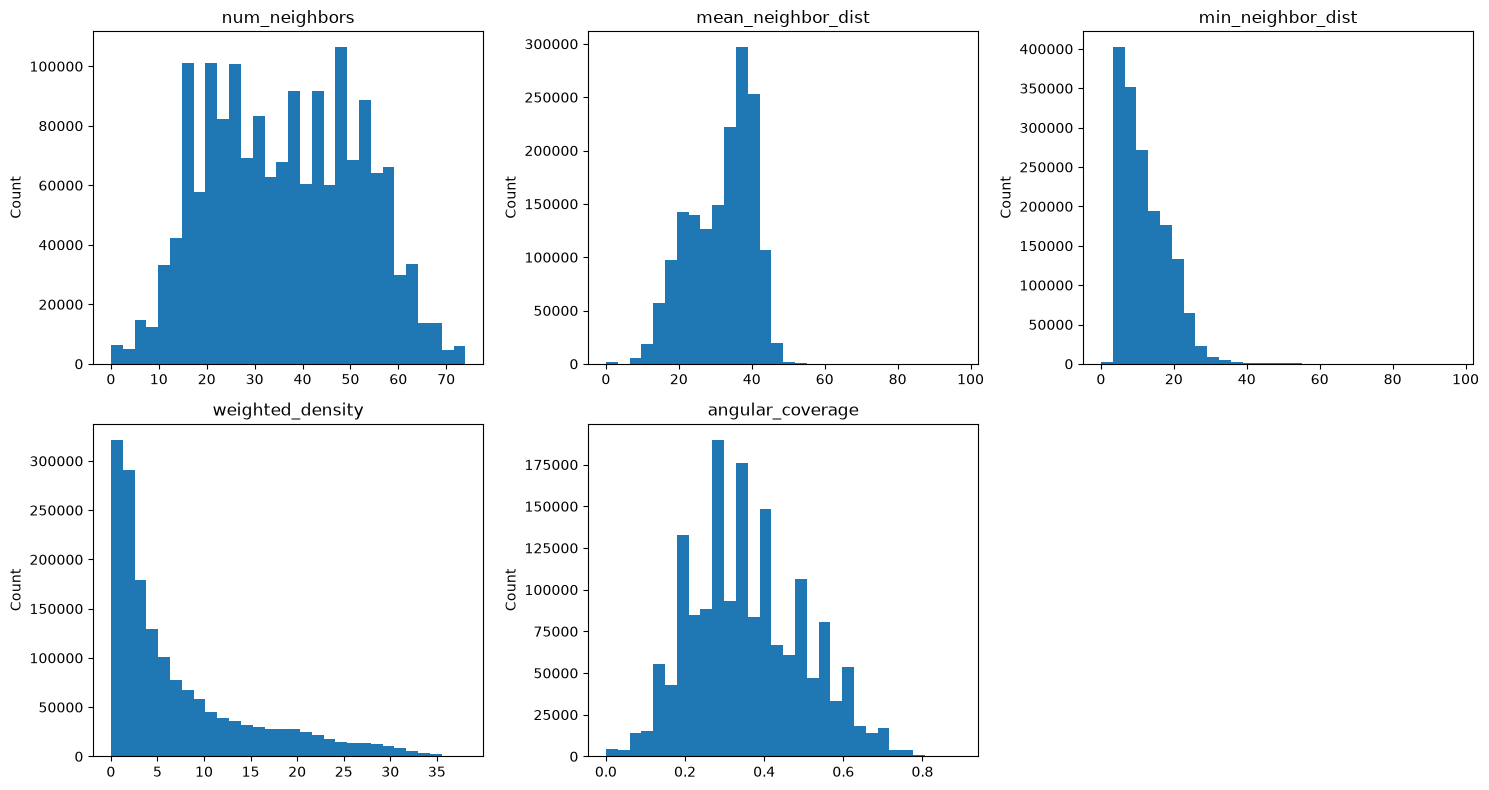

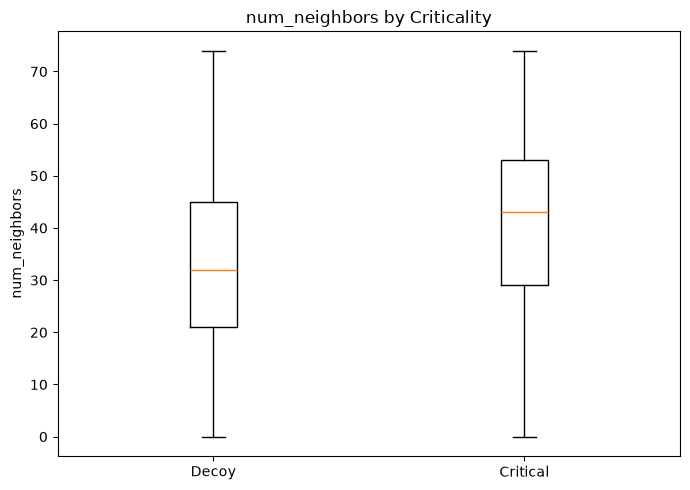

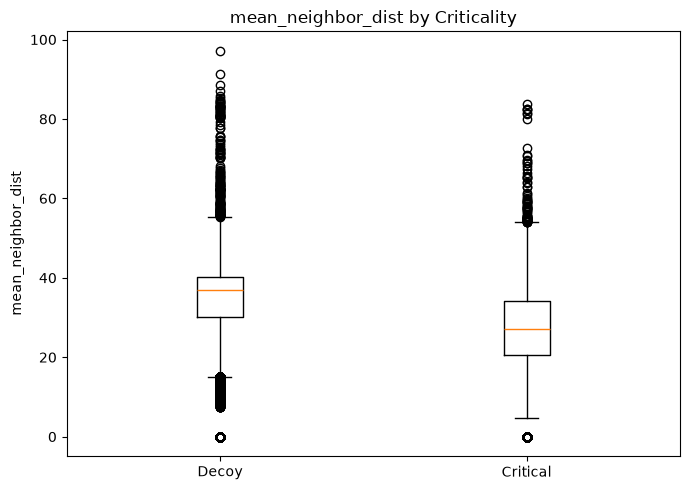

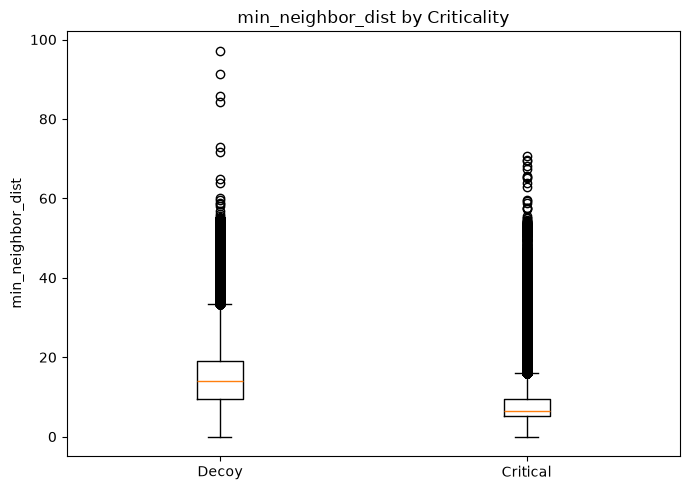

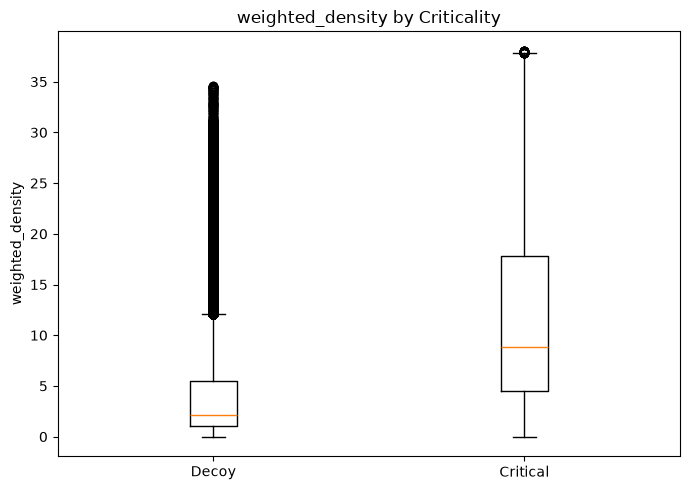

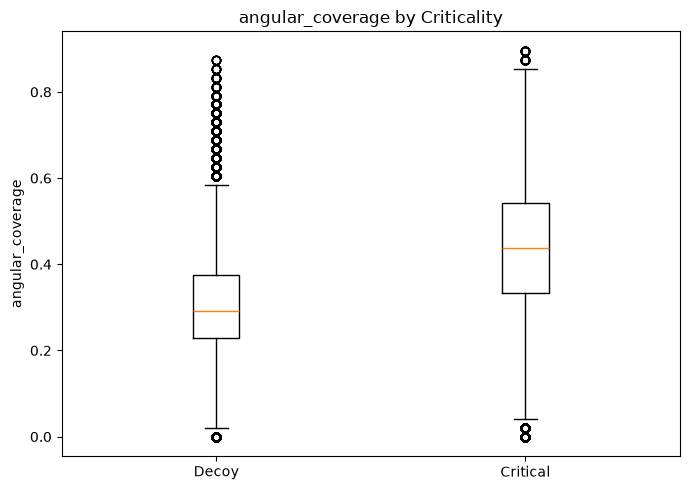

In [43]:
local_features = ["num_neighbors", "mean_neighbor_dist", "min_neighbor_dist",
                  "weighted_density", "angular_coverage"]

# histograms
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i in range(len(local_features)):
    axes[i].hist(df[local_features[i]].dropna(), bins=30)
    axes[i].set_title(local_features[i])
    axes[i].set_ylabel("Count")
axes[5].axis("off")
plt.tight_layout()
plt.show()

# boxplots by target
for col in local_features:
    decoy = df[df["is_critical"] == 0][col].dropna()
    critical = df[df["is_critical"] == 1][col].dropna()

    plt.figure(figsize=(7, 5))
    plt.boxplot([decoy, critical])
    plt.xticks([1, 2], ["Decoy", "Critical"])
    plt.ylabel(col)
    plt.title(col + " by Criticality")
    plt.tight_layout()
    plt.show()

## 44. Graph centrality distributions and target comparisons

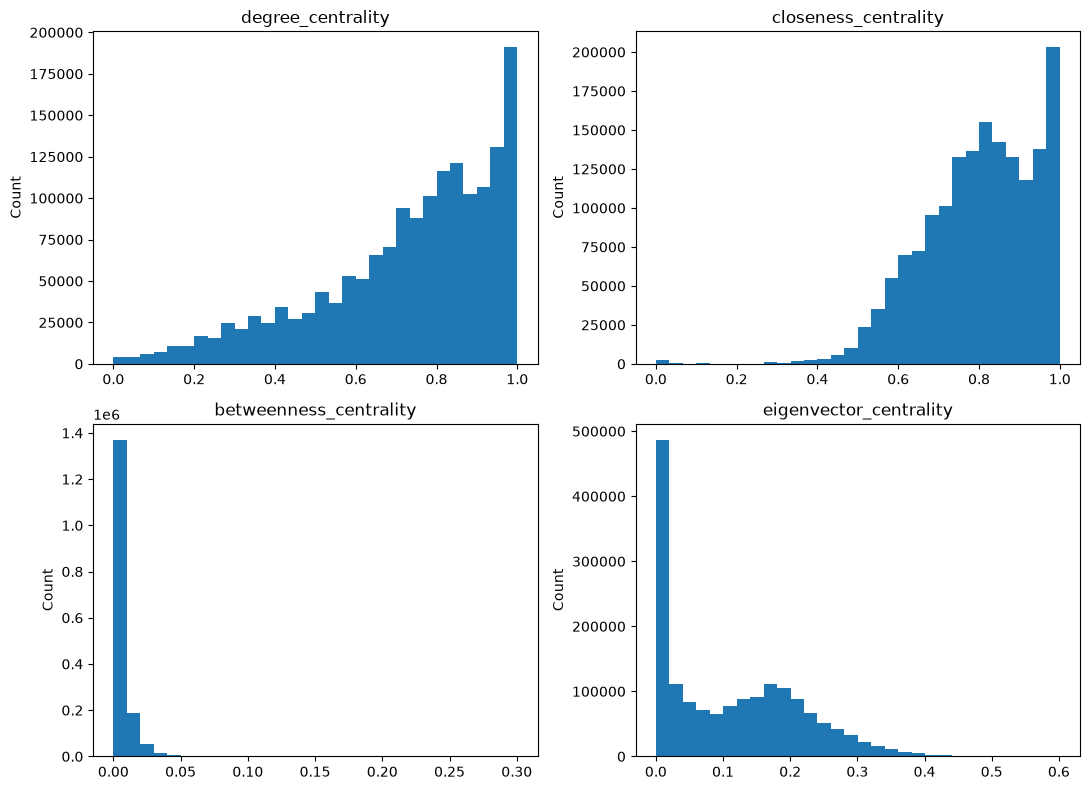

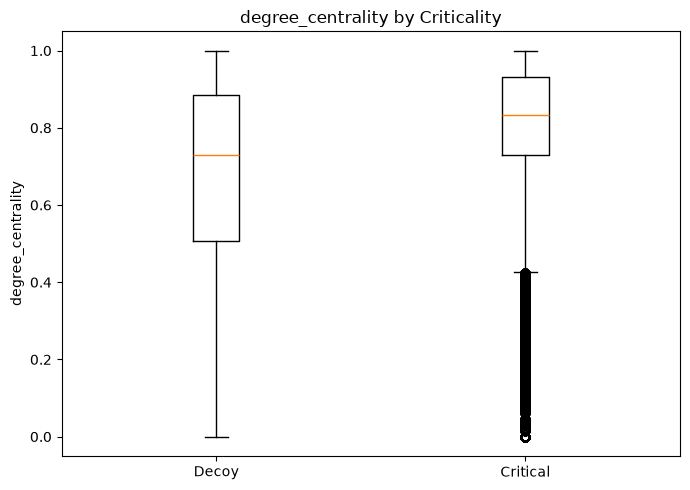

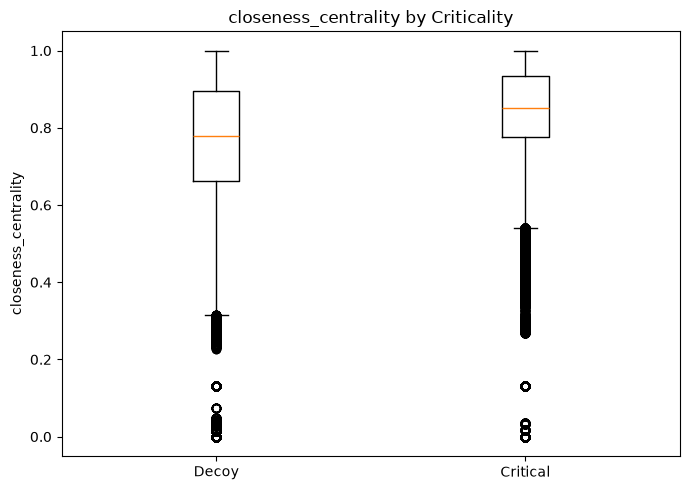

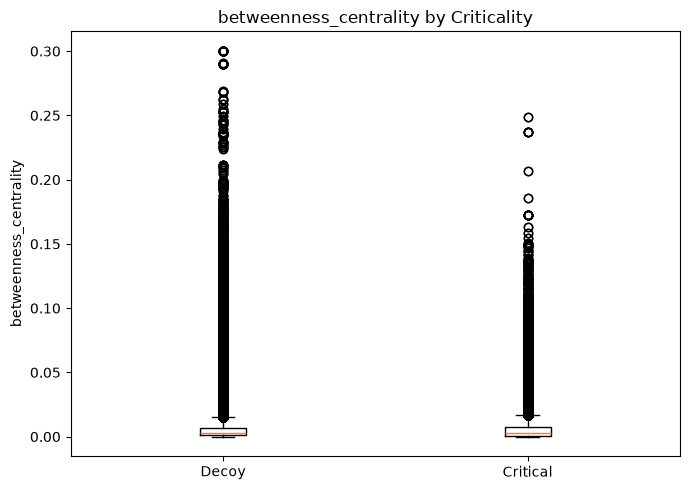

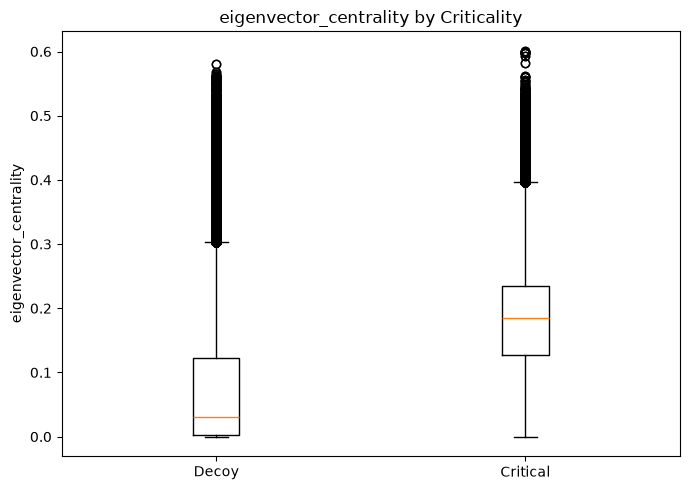

In [44]:
graph_features = ["degree_centrality", "closeness_centrality",
                  "betweenness_centrality", "eigenvector_centrality"]

# histograms
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()
for i in range(len(graph_features)):
    axes[i].hist(df[graph_features[i]].dropna(), bins=30)
    axes[i].set_title(graph_features[i])
    axes[i].set_ylabel("Count")
plt.tight_layout()
plt.show()

# boxplots by target
for col in graph_features:
    decoy = df[df["is_critical"] == 0][col].dropna()
    critical = df[df["is_critical"] == 1][col].dropna()

    plt.figure(figsize=(7, 5))
    plt.boxplot([decoy, critical])
    plt.xticks([1, 2], ["Decoy", "Critical"])
    plt.ylabel(col)
    plt.title(col + " by Criticality")
    plt.tight_layout()
    plt.show()

## 45. Correlation between local geometry and graph features

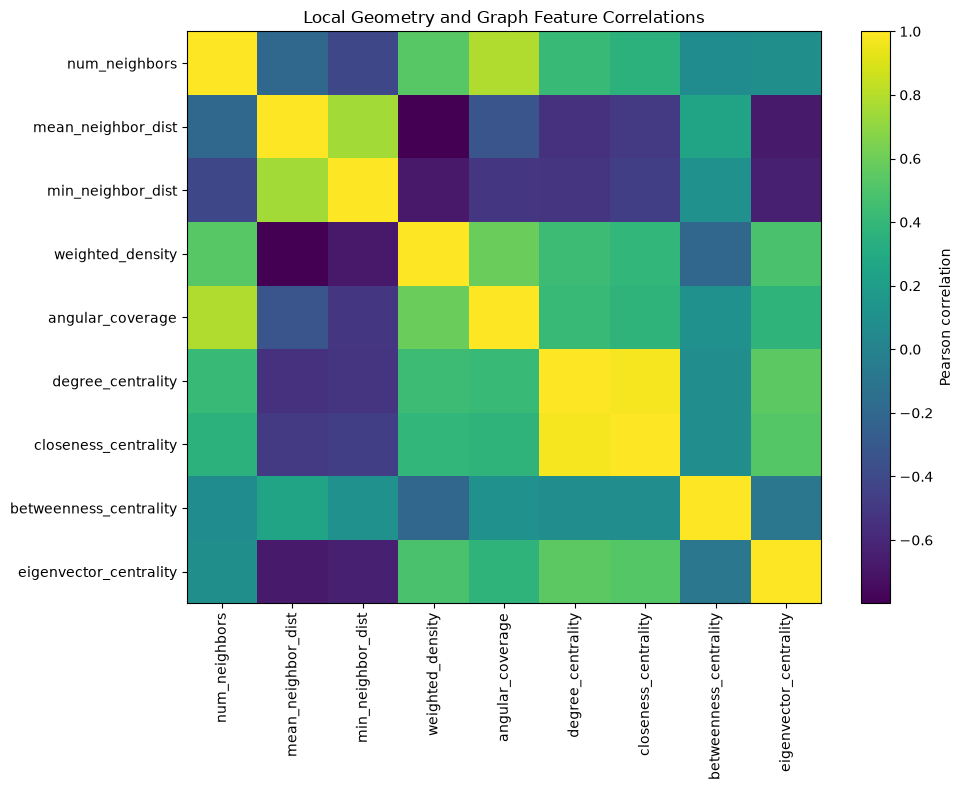

,num_neighbors,mean_neighbor_dist,min_neighbor_dist,weighted_density,angular_coverage,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality
num_neighbors,1.0000,-0.1911,-0.4070,0.5309,0.7832,0.4220,0.3551,0.0765,0.0985
mean_neighbor_dist,-0.1911,1.0000,0.7537,-0.7988,-0.3243,-0.5423,-0.4948,0.2509,-0.6682
min_neighbor_dist,-0.4070,0.7537,1.0000,-0.6761,-0.5117,-0.5181,-0.4623,0.1127,-0.6417
weighted_density,0.5309,-0.7988,-0.6761,1.0000,0.5921,0.4374,0.3893,-0.2064,0.4824
angular_coverage,0.7832,-0.3243,-0.5117,0.5921,1.0000,0.4118,0.3717,0.1105,0.3696
degree_centrality,0.4220,-0.5423,-0.5181,0.4374,0.4118,1.0000,0.9738,0.0809,0.5486
closeness_centrality,0.3551,-0.4948,-0.4623,0.3893,0.3717,0.9738,1.0000,0.0838,0.5265
betweenness_centrality,0.0765,0.2509,0.1127,-0.2064,0.1105,0.0809,0.0838,1.0000,-0.0847
eigenvector_centrality,0.0985,-0.6682,-0.6417,0.4824,0.3696,0.5486,0.5265,-0.0847,1.0000


In [45]:
graph_local = local_features + graph_features
graph_corr = df[graph_local].corr()

plt.figure(figsize=(10, 8))
plt.imshow(graph_corr, aspect="auto", interpolation="nearest")
plt.xticks(range(len(graph_corr.columns)), graph_corr.columns, rotation=90)
plt.yticks(range(len(graph_corr.columns)), graph_corr.columns)
plt.colorbar(label="Pearson correlation")
plt.title("Local Geometry and Graph Feature Correlations")
plt.tight_layout()
plt.show()

graph_corr

## 46. Environment values and distributions

In [46]:
for col in ["num_agents", "n_obstacles", "attrition_rate"]:
    print(col)
    print(df[col].value_counts())
    print()

environment_numeric = ["obstacle_density", "mean_obstacle_size", "clutter_index", "obstacle_clustering"]
df[environment_numeric].describe().T

num_agents
num_agents
75    426099
60    225848
68    218077
52    192729
45    155687
30    145605
24    113679
37     87241
18     74201
Name: count, dtype: int64

n_obstacles
n_obstacles
1     263454
6     234248
5     195157
3     171140
2     136128
4     122359
12    113716
0      84901
8      78480
7      75474
9      65265
11     57902
10     40942
Name: count, dtype: int64

attrition_rate
attrition_rate
light     427209
none      421477
medium    421367
heavy     369113
Name: count, dtype: int64



,count,mean,std,min,25%,50%,75%,max
obstacle_density,1639166.0000,0.1068,0.0991,0.0000,0.0373,0.0893,0.1427,0.6415
mean_obstacle_size,1639166.0000,14.0799,6.4911,0.0000,9.5880,13.8655,18.0581,32.0000
clutter_index,1639166.0000,0.6008,0.2978,0.0000,0.3517,0.7333,0.8000,1.0000
obstacle_clustering,1639166.0000,0.5255,0.2502,0.0403,0.3415,0.5253,0.7300,0.9979


## 47. Critical fraction versus initial swarm size

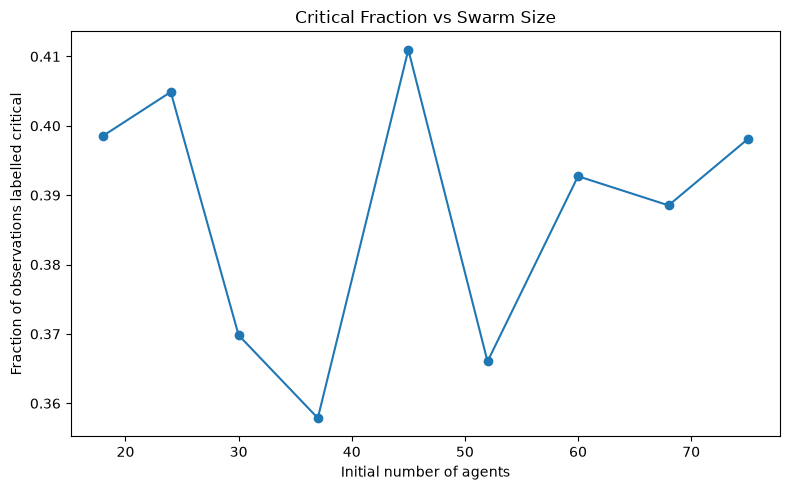

In [47]:
swarm_target = df.groupby("num_agents")["is_critical"].mean()

plt.figure(figsize=(8, 5))
plt.plot(swarm_target.index, swarm_target.values, marker="o")
plt.xlabel("Initial number of agents")
plt.ylabel("Fraction of observations labelled critical")
plt.title("Critical Fraction vs Swarm Size")
plt.tight_layout()
plt.show()

## 48. Attrition distribution and target composition

attrition_rate
light     427209
none      421477
medium    421367
heavy     369113
Name: count, dtype: int64
is_critical      False   True 
attrition_rate                
heavy          57.6558 42.3442
light          63.4844 36.5156
medium         60.4490 39.5510
none           62.2058 37.7942


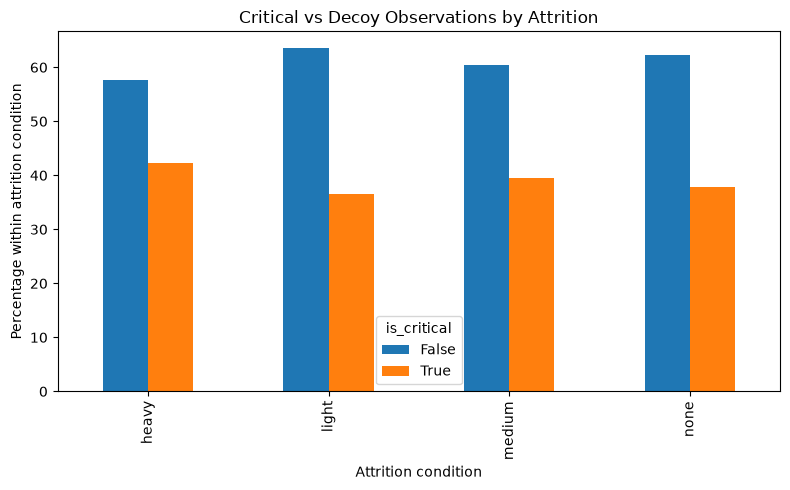

In [48]:
print(df["attrition_rate"].value_counts())

attrition_target = pd.crosstab(df["attrition_rate"], df["is_critical"], normalize="index") * 100
print(attrition_target)

attrition_target.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Attrition condition")
plt.ylabel("Percentage within attrition condition")
plt.title("Critical vs Decoy Observations by Attrition")
plt.legend(title="is_critical")
plt.tight_layout()
plt.show()

## 49. How attrition relates to local and graph structure

In [49]:
attrition_features = ["num_neighbors", "mean_neighbor_dist", "min_neighbor_dist",
                      "weighted_density", "angular_coverage", "degree_centrality",
                      "closeness_centrality", "betweenness_centrality",
                      "eigenvector_centrality"]

df.groupby("attrition_rate")[attrition_features].mean()

,num_neighbors,mean_neighbor_dist,min_neighbor_dist,weighted_density,angular_coverage,degree_centrality,closeness_centrality,betweenness_centrality,eigenvector_centrality
attrition_rate,,,,,,,,,
heavy,36.2284,31.0984,11.7380,7.5275,0.3553,0.7547,0.8166,0.0052,0.1196
light,38.1249,31.7391,12.0441,7.8416,0.3716,0.7231,0.7970,0.0055,0.1092
medium,33.8852,30.9979,11.7422,7.0443,0.3449,0.7404,0.8071,0.0058,0.1158
none,36.6384,32.7762,12.2193,6.5719,0.3679,0.7095,0.7877,0.0058,0.1066


## 50. Temporal trends in selected features

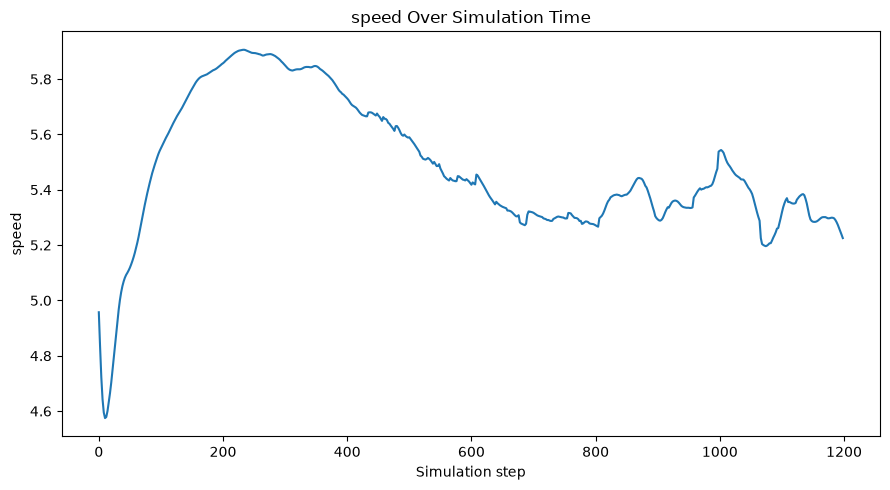

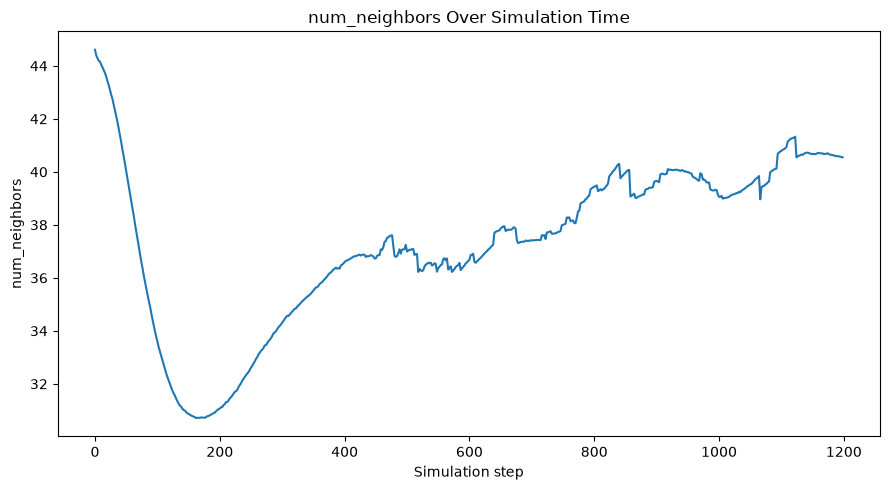

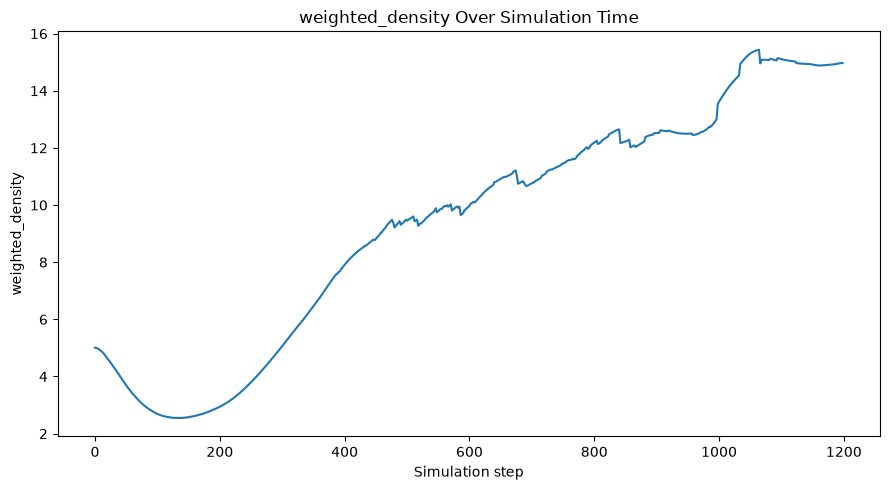

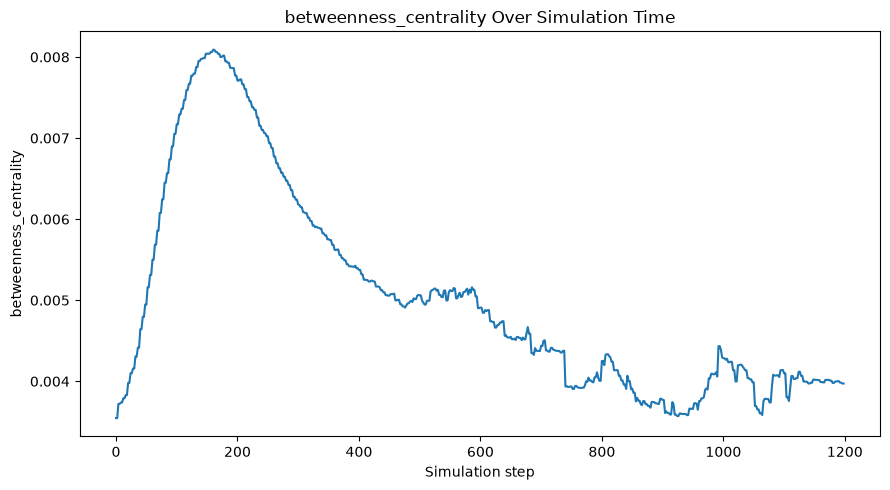

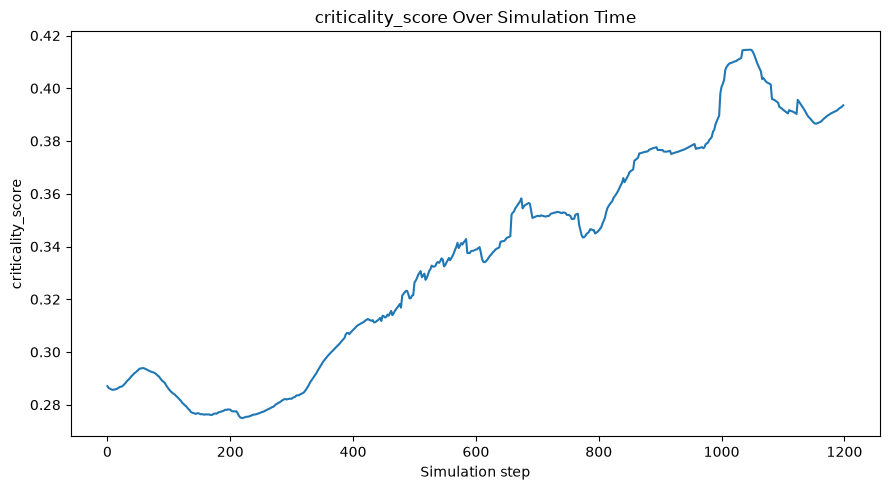

In [50]:
temporal_features = ["speed", "num_neighbors", "weighted_density",
                     "betweenness_centrality", "criticality_score"]

for col in temporal_features:
    temporal_mean = df.groupby("step")[col].mean()

    plt.figure(figsize=(9, 5))
    plt.plot(temporal_mean.index, temporal_mean.values)
    plt.xlabel("Simulation step")
    plt.ylabel(col)
    plt.title(col + " Over Simulation Time")
    plt.tight_layout()
    plt.show()

## 51. Investigate criticality_score for possible target leakage

                   count   mean    std    min    25%    50%    75%    max
is_critical                                                              
False       1000921.0000 0.0339 0.0542 0.0000 0.0078 0.0193 0.0397 0.6108
True         638245.0000 0.7513 0.2093 0.0000 0.6075 0.8055 0.9284 1.0000


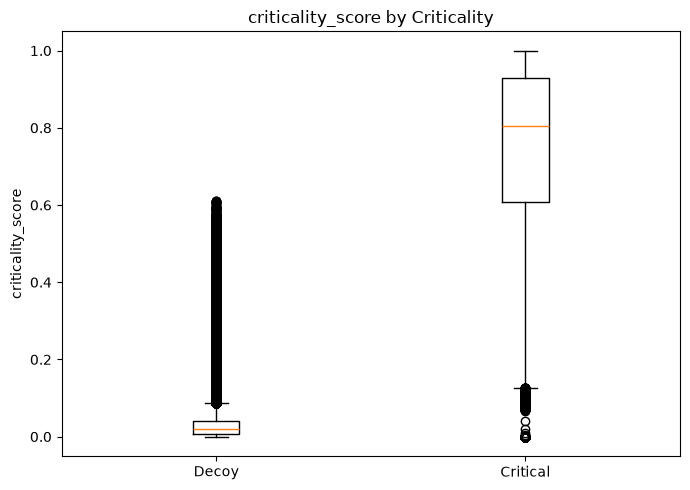

                   criticality_score  is_critical
criticality_score             1.0000       0.9309
is_critical                   0.9309       1.0000


In [51]:
print(df.groupby("is_critical")["criticality_score"].describe())

decoy = df[df["is_critical"] == 0]["criticality_score"]
critical = df[df["is_critical"] == 1]["criticality_score"]

plt.figure(figsize=(7, 5))
plt.boxplot([decoy, critical])
plt.xticks([1, 2], ["Decoy", "Critical"])
plt.ylabel("criticality_score")
plt.title("criticality_score by Criticality")
plt.tight_layout()
plt.show()

print(df[["criticality_score", "is_critical"]].corr())

## 52. Summarize each simulation case

                 num_agents  n_obstacles attrition  observations  \
case_id                                                            
c001_n60_none            60            2      none         13020   
c002_n30_medium          30            7    medium         16705   
c003_n37_medium          37            2    medium         15885   
c004_n30_heavy           30            0     heavy          7826   
c005_n52_heavy           52            6     heavy         27836   

                 critical_observation_fraction  
case_id                                         
c001_n60_none                           0.4000  
c002_n30_medium                         0.3233  
c003_n37_medium                         0.3359  
c004_n30_heavy                          0.4991  
c005_n52_heavy                          0.3880  


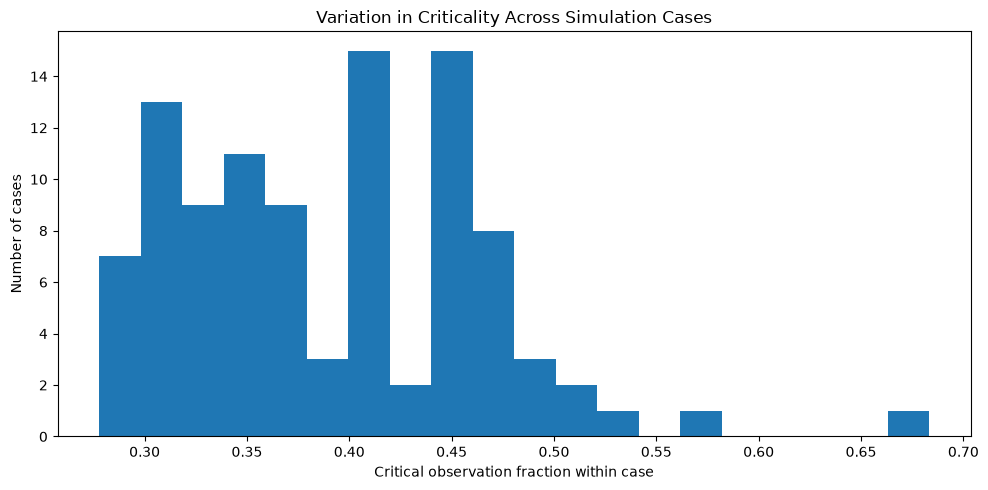

In [52]:
case_summary = df.groupby("case_id").agg(
    num_agents=("num_agents", "first"),
    n_obstacles=("n_obstacles", "first"),
    attrition=("attrition_rate", "first"),
    observations=("case_id", "size"),
    critical_observation_fraction=("is_critical", "mean"),
)
print(case_summary.head())

plt.figure(figsize=(10, 5))
plt.hist(case_summary["critical_observation_fraction"], bins=20)
plt.xlabel("Critical observation fraction within case")
plt.ylabel("Number of cases")
plt.title("Variation in Criticality Across Simulation Cases")
plt.tight_layout()
plt.show()